# IAU 140
Hugo Foltin - 50%, Teodor Potančok - 50%

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

## Základný opis dát spolu s ich charakteristikami


### 1.1 A
* V tejto časti pre všetky dátové súbory zistíme ich štruktúru, rozmery, dátové typy, pamäťovú náročnosť a výskyt chýbajúcich hodnôt 

In [2]:
units = pd.read_csv("data/units.csv", sep=",")
readings = pd.read_csv("data/readings.csv", sep="\t")
gateways = pd.read_csv("data/gateways.csv", sep=";")

print("SÚHRN ROZMEROV DÁTOVÝCH SAD")
print(f"units.csv:    {units.shape[0]:>6} riadkov, {units.shape[1]:>2} stĺpcov")
print(f"readings.csv: {readings.shape[0]:>6} riadkov, {readings.shape[1]:>2} stĺpcov")
print(f"gateways.csv: {gateways.shape[0]:>6} riadkov, {gateways.shape[1]:>2} stĺpcov")

SÚHRN ROZMEROV DÁTOVÝCH SAD
units.csv:      2000 riadkov,  7 stĺpcov
readings.csv:  12313 riadkov, 15 stĺpcov
gateways.csv:  16000 riadkov,  8 stĺpcov


In [3]:
def analyze_structure(df, name):
    summary = pd.DataFrame(
        {
            "Dátový typ": df.dtypes.astype(str),
            "Non-Null Počet": df.notnull().sum(),
            "Null Počet": df.isnull().sum(),
            "Null Podiel (%)": (df.isnull().sum() / len(df) * 100).round(2),
            "Počet unikátnych": df.nunique(),
            "Ukážka hodnoty": df.iloc[0].values,
        }
    )
    print(
        f"\nŠtruktúra tabuľky: {name} ({df.shape[0]} riadkov, {df.shape[1]} stĺpcov, {df.memory_usage().sum() / 1024:.1f} KB)"
    )
    return summary


print("1. UNITS:")
display(analyze_structure(units, "units.csv"))

print("\n2. READINGS:")
display(analyze_structure(readings, "readings.csv"))

print("\n3. GATEWAYS:")
display(analyze_structure(gateways, "gateways.csv"))

1. UNITS:

Štruktúra tabuľky: units.csv (2000 riadkov, 7 stĺpcov, 109.5 KB)


,Dátový typ,Non-Null Počet,Null Počet,Null Podiel (%),Počet unikátnych,Ukážka hodnoty
depot_id,int64,2000,0,0.0,120,12
code_fleet,str,2000,0,0.0,5,FB
id_unit,int64,2000,0,0.0,2000,1
duty_class,str,2000,0,0.0,20,1
service_hours,float64,1900,100,5.0,1871,8329.4
install_region,str,2000,0,0.0,58,Fürstenfeldbruck
codeModel,str,2000,0,0.0,4,XC-7



2. READINGS:

Štruktúra tabuľky: readings.csv (12313 riadkov, 15 stĺpcov, 1443.1 KB)


,Dátový typ,Non-Null Počet,Null Počet,Null Podiel (%),Počet unikátnych,Ukážka hodnoty
id_unit,str,12313,0,0.00,2111,U01083
cycleTs,str,12313,0,0.00,4065,"06/22/2023, 13:51:00"
motorCurrent,float64,12313,0,0.00,12007,4.10064
filterDp,float64,11782,531,4.31,11584,NaN
oil_temperature,float64,12313,0,0.00,12080,81.25839
reservoirPressure,float64,12313,0,0.00,11794,8.66503
pressure_working,float64,12313,0,0.00,11771,8.55913
oilPressure,float64,12313,0,0.00,11768,3.71709
vibrationRms,float64,11799,514,4.17,11447,2.11896
flowmeter,float64,12313,0,0.00,12056,30.07764



3. GATEWAYS:

Štruktúra tabuľky: gateways.csv (16000 riadkov, 8 stĺpcov, 1000.1 KB)


,Dátový typ,Non-Null Počet,Null Počet,Null Podiel (%),Počet unikátnych,Ukážka hodnoty
gatewayId,str,16000,0,0.0,16000,GW-00000
depot_id,int64,16000,0,0.0,120,17
installDate,str,16000,0,0.0,9669,2023/05/29
mac_address,str,16000,0,0.0,16000,66:3a:5c:ca:d9:c6
id_unit,float64,2000,14000,87.5,2000,1525.0
Lon,float64,16000,0,0.0,15594,-8.18846
versionFirmware,str,16000,0,0.0,3,v2.7.0
model_hardware,str,16000,0,0.0,5,GWX-300


## 1.2 Čistenie datasetu

Vidíme že polia v datasete majú nekonzistentné názvy - `depot_id` vs `id_unit`, `versionFirmware` vs `model_hardware`. Aby sa s dátami lepšie pracovalo musíme ich premenovať aby používali jednu konvenciu. V Pythone sa štandardne používa `camel_case` preto aj my prejdeme na tento štýl.

In [4]:
units.rename(
    columns={
        "code_fleet": "fleet_code",
        "id_unit": "unit_id",
        "codeModel": "model_code",
    },
    inplace=True,
)
units.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   depot_id        2000 non-null   int64  
 1   fleet_code      2000 non-null   str    
 2   unit_id         2000 non-null   int64  
 3   duty_class      2000 non-null   str    
 4   service_hours   1900 non-null   float64
 5   install_region  2000 non-null   str    
 6   model_code      2000 non-null   str    
dtypes: float64(1), int64(2), str(4)
memory usage: 109.5 KB


In [5]:
readings.rename(
    columns={
        "id_unit": "unit_id",
        "cycleTs": "cycle_timestamp",
        "motorCurrent": "motor_current",
        "filterDp": "filter_dp",
        "reservoirPressure": "reservoir_pressure",
        "pressure_working": "working_pressure",
        "oilPressure": "oil_pressure",
        "vibrationRms": "vibration_rms",
        "flowmeter": "flow_meter",
        "humidityIntake": "humidity_intake",
        "dischargeDewpoint": "discharge_dewpoint",
        "current_aux": "aux_current",
        "Failure": "failure",
    },
    inplace=True,
)
readings.info()

<class 'pandas.DataFrame'>
RangeIndex: 12313 entries, 0 to 12312
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   unit_id             12313 non-null  str    
 1   cycle_timestamp     12313 non-null  str    
 2   motor_current       12313 non-null  float64
 3   filter_dp           11782 non-null  float64
 4   oil_temperature     12313 non-null  float64
 5   reservoir_pressure  12313 non-null  float64
 6   working_pressure    12313 non-null  float64
 7   oil_pressure        12313 non-null  float64
 8   vibration_rms       11799 non-null  float64
 9   flow_meter          12313 non-null  float64
 10  humidity_intake     11714 non-null  float64
 11  ambient_noise       12313 non-null  float64
 12  discharge_dewpoint  12313 non-null  float64
 13  aux_current         12313 non-null  float64
 14  failure             12313 non-null  int64  
dtypes: float64(12), int64(1), str(2)
memory usage: 1.4 MB


In [6]:
gateways.rename(
    columns={
        "gatewayId": "gateway_id",
        "installDate": "install_date",
        "id_unit": "unit_id",
        "Lon": "longitude",
        "versionFirmware": "firmware_version",
        "model_hardware": "hardware_model",
    },
    inplace=True,
)
gateways.info()

<class 'pandas.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gateway_id        16000 non-null  str    
 1   depot_id          16000 non-null  int64  
 2   install_date      16000 non-null  str    
 3   mac_address       16000 non-null  str    
 4   unit_id           2000 non-null   float64
 5   longitude         16000 non-null  float64
 6   firmware_version  16000 non-null  str    
 7   hardware_model    16000 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 1000.1 KB


Mimo toho vidíme že v `gateways` je veľa záznamov v ktorých nemáme kompletné údaje - chýba `filter_dp`, `vibration_rms` alebo `humidity_intake`. Pre začiatok zistíme koľko ich je:

In [7]:
readings.isna().sum()

unit_id                 0
cycle_timestamp         0
motor_current           0
filter_dp             531
oil_temperature         0
reservoir_pressure      0
working_pressure        0
oil_pressure            0
vibration_rms         514
flow_meter              0
humidity_intake       599
ambient_noise           0
discharge_dewpoint      0
aux_current             0
failure                 0
dtype: int64

In [8]:
readings.dropna().shape[0] / readings.shape[0] * 100

87.55786567042962

Po odstránení poškodených záznamov ich stále zostane viac ako 87%, preto sa to určite oplatí a môžeme pokračovať bez nich.

In [9]:
readings.dropna(inplace=True)

V tabuľke `gateways` je iný problém, máme 16 000 záznamov ale len 2 000 z nich má `unit_id` ktorý potrebujeme na prepojenie s `units` a `readings`. Podľa všetkého to je zoznam sieťového vybavenie (máme MAC adresy a názvy modelov ako `NODE-9`), z ktorého väčšina nesúvisí s dopravným systémom. Záznamy bez `unit_id` sú pre nás zbytočné a je lepšie ich odstrániť.

In [10]:
gateways.dropna(inplace=True)

In [11]:
gateways.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gateway_id        2000 non-null   str    
 1   depot_id          2000 non-null   int64  
 2   install_date      2000 non-null   str    
 3   mac_address       2000 non-null   str    
 4   unit_id           2000 non-null   float64
 5   longitude         2000 non-null   float64
 6   firmware_version  2000 non-null   str    
 7   hardware_model    2000 non-null   str    
dtypes: float64(2), int64(1), str(5)
memory usage: 125.1 KB


Posledná chyba je v tabuľke `units` kde pri 100 záznamoch z 2000 chýba hodnota `service_hours`. Tieto záznamy musíme odstrániť pretože údaj o služobnom veku vozidla je vždy dôležitý pri predpovedaní technických problémov alebo plánovaní kontroly.

In [12]:
units.dropna(inplace=True)

In [13]:
units.info()

<class 'pandas.DataFrame'>
Index: 1900 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   depot_id        1900 non-null   int64  
 1   fleet_code      1900 non-null   str    
 2   unit_id         1900 non-null   int64  
 3   duty_class      1900 non-null   str    
 4   service_hours   1900 non-null   float64
 5   install_region  1900 non-null   str    
 6   model_code      1900 non-null   str    
dtypes: float64(1), int64(2), str(4)
memory usage: 118.8 KB


### Normalizácia a dátové typy

Pri niektorých atribútoch vidíme že sú reprezentované nevhodným typom - `str` pre dátumy a kategorické premenné, `int64` pre boolean hodnotu `failure`. Napríklad v `units.duty_class` je jedna kategória zapísaná viac ako 3 spôsobmi:

In [14]:
units["duty_class"].unique()

<StringArray>
[       '1',        'L',        '2',    'heavy',      ' 3 ',      'med',
      ' 2 ',   'normal',        'H',    'light',      ' 1 ',  ' light ',
        'N',        '3', ' normal ',      ' H ',  ' heavy ',      ' N ',
      ' L ',    ' med ']
Length: 20, dtype: str

Problém vyriešime tak že ho prevedieme na `dtype=category` a normalizujeme hodnoty na jeden label pre každú kategóriu. Problém je že nevieme v akom poradí sú číselné kategórie - znamená 1 to isté čo "light" alebo "heavy"? Na to aby sme to zistili musíme porovnať ich rozdelenie.

<Axes: xlabel='duty_class', ylabel='Count'>

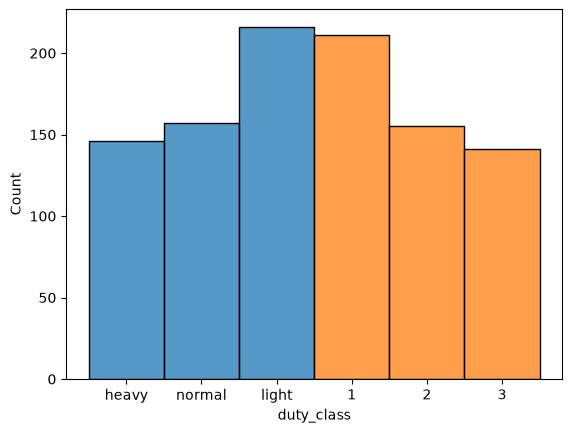

In [15]:
text_classes = ["light", "normal", "heavy"]
num_classes = ["1", "2", "3"]

sns.histplot(units.loc[units["duty_class"].isin(text_classes)]["duty_class"])
sns.histplot(units.loc[units["duty_class"].isin(num_classes)]["duty_class"])

Vidíme že v prvej časti grafu od "heavy" po "light" počet vozidiel stúpa, ale v druhej od 1 po 3 klesá - vznikol zrkadlový obraz. Z toho môžeme predpokladať že kategórie v grafe sú **naopak** - "1" v skutočnosti zodpovedá "light".

Teraz keď vieme čo ktorá hodnota znamená ich namapujeme na štandardné kategórie "light", "normal" a "heavy". Ešte pred tým ale odstránime whitespace na začiatku a konci záznamov.

In [16]:
mapping = {
    "1": "light",
    "2": "normal",
    "3": "heavy",
    "L": "light",
    "N": "normal",
    "H": "heavy",
    "med": "normal",
}


def clean_duty_class(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip()
    return mapping.get(value, value)


units["duty_class"] = units["duty_class"].map(clean_duty_class).astype("category")

units["duty_class"].unique()

['light', 'normal', 'heavy']
Categories (3, str): ['heavy', 'light', 'normal']

In [17]:
units.head(10)

,depot_id,fleet_code,unit_id,duty_class,service_hours,install_region,model_code
0,12,FB,1,light,8329.4,Fürstenfeldbruck,XC-7
1,110,FA,2,light,6371.8,Güstrow,APU-15
2,30,FD,3,light,16268.2,New Jasonfort,APU-20
3,52,FA,4,normal,9524.6,Heinsberg,APU-15
4,114,FB,5,heavy,28956.7,Güstrow,APU-15
5,116,FA,6,heavy,45000.0,Dachau,APU-20
6,73,FB,7,normal,6915.6,Großenhain,APU-20
7,55,FA,8,normal,9814.3,Jülich,APU-20
8,53,FC,9,heavy,4918.2,New Jasonfort,APU-12
9,67,FA,10,normal,9910.4,Wismar,APU-12


Druhý problém je formát `unit_id` - v `readings` je to text ako "U00679" aj keď v `units` máme normálne čísla. Textové ID prevedieme na čísla aby sa s nimi lepšie pracovalo.

In [18]:
readings["unit_id"] = readings["unit_id"].map(lambda x: int(x[1:])).astype("int32")

readings.head()

,unit_id,cycle_timestamp,motor_current,filter_dp,oil_temperature,reservoir_pressure,working_pressure,oil_pressure,vibration_rms,flow_meter,humidity_intake,ambient_noise,discharge_dewpoint,aux_current,failure
1,256,"12/10/2023, 14:32:00",4.42042,20.58792,47.21276,9.23927,9.25717,3.96332,2.36210,32.31361,19.98362,73.66297,5.84201,3.76478,0
2,1652,"07/17/2023, 20:32:00",4.90300,28.52708,68.02586,8.29539,8.24885,3.81932,3.28220,23.63779,71.02485,68.67375,6.69999,2.66410,0
3,529,2023-12-22,6.08280,20.98545,58.11114,8.95545,9.07570,3.39484,5.42669,26.31633,37.04884,75.67641,11.91813,1.58497,0
4,697,2023/01/29,6.69522,21.32718,70.81750,8.54513,8.56433,3.82058,7.90080,24.22535,71.22240,64.90649,5.94331,4.15007,0
5,1127,2023-06-14,6.35664,16.33700,52.16693,8.99387,8.73377,4.21274,2.18324,30.36919,17.35623,77.78946,16.39197,2.65400,0


Posledná vec ktorú musíme riešiť je formát dátumov. V tabuľkách sú reprezentované ako text v rôznych tvaroch - ISO formát `2023-12-22`, americký s časom `07/19/2023, 14:08:00` alebo európsky so skratkou mesiaca `16 Aug 2023`. Pandas má funkciu `to_datetime` ktorá vie všetky prečítať a vyrobiť z nich objekt typu `datetime64[us]`.

In [19]:
dates = pd.to_datetime(readings["cycle_timestamp"], format="mixed", cache=True).dt.date
dates

1        2023-12-10
2        2023-07-17
3        2023-12-22
4        2023-01-29
5        2023-06-14
            ...    
12307    2023-01-31
12308    2023-12-23
12309    2023-09-15
12311    2023-08-04
12312    2023-05-11
Name: cycle_timestamp, Length: 10781, dtype: object

In [20]:
readings["cycle_timestamp"] = dates
readings.head()

,unit_id,cycle_timestamp,motor_current,filter_dp,oil_temperature,reservoir_pressure,working_pressure,oil_pressure,vibration_rms,flow_meter,humidity_intake,ambient_noise,discharge_dewpoint,aux_current,failure
1,256,2023-12-10,4.42042,20.58792,47.21276,9.23927,9.25717,3.96332,2.36210,32.31361,19.98362,73.66297,5.84201,3.76478,0
2,1652,2023-07-17,4.90300,28.52708,68.02586,8.29539,8.24885,3.81932,3.28220,23.63779,71.02485,68.67375,6.69999,2.66410,0
3,529,2023-12-22,6.08280,20.98545,58.11114,8.95545,9.07570,3.39484,5.42669,26.31633,37.04884,75.67641,11.91813,1.58497,0
4,697,2023-01-29,6.69522,21.32718,70.81750,8.54513,8.56433,3.82058,7.90080,24.22535,71.22240,64.90649,5.94331,4.15007,0
5,1127,2023-06-14,6.35664,16.33700,52.16693,8.99387,8.73377,4.21274,2.18324,30.36919,17.35623,77.78946,16.39197,2.65400,0


In [21]:
dates = pd.to_datetime(gateways["install_date"], format="mixed", cache=True)
dates

0      2023-05-29
1      2016-02-17
2      2024-01-09
3      2016-08-03
4      2017-01-10
          ...    
1995   2023-08-02
1996   2023-02-22
1997   2023-04-08
1998   2023-11-10
1999   2024-01-16
Name: install_date, Length: 2000, dtype: datetime64[us]

In [22]:
gateways["install_date"] = dates
gateways.head()

,gateway_id,depot_id,install_date,mac_address,unit_id,longitude,firmware_version,hardware_model
0,GW-00000,17,2023-05-29,66:3a:5c:ca:d9:c6,1525.0,-8.18846,v2.7.0,GWX-300
1,GW-00001,10,2016-02-17,a9:5a:0c:43:79:4c,1246.0,-7.18343,v3.4.1,GWX-300
2,GW-00002,62,2024-01-09,74:2c:b1:e6:cc:d1,1126.0,-7.09603,v2.7.0,NODE-7
3,GW-00003,80,2016-08-03,ee:8b:e5:9f:32:d5,286.0,-8.00555,v1.2.5,GWX-200
4,GW-00004,59,2017-01-10,78:e0:26:14:49:18,266.0,-8.34452,v2.7.0,GWX-300


### Extrémne hodnoty

Grafy pre `motor_current` a `oil_temperature` v úlohe 1.1 ukazujú abnormálne hodnoty. Takmer všetky merania sú blízko mediánov (5.15 a 3.7), ale maximálna hodnota `motor_current` je 99 a minimálna `oil_temperature` je -999. Teplota -999°C nie je realistická a prúd ktorý je 25x vyšší ako normálne by mal zvýšiť podiel `failure` čo v dátach nevidíme. Podľa všetkého ide o chybné merania ktoré musíme z datasetu odstrániť.

In [23]:
readings[readings["motor_current"] > 10.0].head(5)

,unit_id,cycle_timestamp,motor_current,filter_dp,oil_temperature,reservoir_pressure,working_pressure,oil_pressure,vibration_rms,flow_meter,humidity_intake,ambient_noise,discharge_dewpoint,aux_current,failure
815,733,2023-08-20,99.0,17.84303,54.01992,7.62323,7.46553,2.91796,2.43845,26.01397,63.18847,70.44177,14.28520,1.35216,0
1242,1119,2023-01-30,99.0,13.35413,37.08700,8.93752,8.91813,3.76778,3.33513,23.69204,69.48020,81.51418,3.88582,1.76826,0
1368,270,2023-12-12,99.0,24.12789,62.73665,8.41106,8.79115,3.48836,1.61084,22.99673,57.01314,66.87632,4.85551,2.68077,0
5358,828,2023-08-08,99.0,34.53914,30.99419,8.41495,8.06699,3.21724,2.00541,29.69315,91.90040,84.52444,8.17327,2.92249,0
5464,1555,2023-02-14,99.0,15.82058,47.67103,9.13338,9.30385,3.94514,4.74025,25.87808,20.69822,84.34992,10.30702,1.61888,0


In [24]:
readings[readings["oil_temperature"] < 0.0].head(5)

,unit_id,cycle_timestamp,motor_current,filter_dp,oil_temperature,reservoir_pressure,working_pressure,oil_pressure,vibration_rms,flow_meter,humidity_intake,ambient_noise,discharge_dewpoint,aux_current,failure
524,980,2023-01-28,2.86615,17.83793,-999.0,8.44539,8.52322,2.96577,4.50186,27.28858,37.04932,71.68110,8.02254,2.53012,0
1339,1945,2023-11-08,3.79757,17.81131,-999.0,9.56850,9.45517,4.37952,4.07246,39.45400,49.19142,67.37265,8.90394,3.49274,0
1383,483,2023-03-18,8.02812,34.11724,-999.0,8.78300,8.80960,3.72596,2.71779,31.38009,62.94919,76.45047,4.26819,1.80919,0
1925,1204,2023-08-23,5.46862,24.60103,-999.0,8.16888,8.23566,2.80007,2.54955,23.33304,39.90328,74.70910,7.17132,2.29994,0
1952,171,2023-04-27,7.44281,16.40333,-999.0,8.43152,8.39778,3.10579,2.48771,23.93197,87.73997,70.88948,6.82586,2.14850,0


In [25]:
old_readings = readings.copy()

current = readings["motor_current"]
readings["motor_current"] = current[current < 99.0]

oil_temp = readings["oil_temperature"]
readings["oil_temperature"] = oil_temp[oil_temp > -999.0]

readings.dropna(inplace=True)

Výsledok skontrolujeme cez histogram ktorý by mal ukazovať už len normálne hodnoty.

<Axes: xlabel='oil_temperature', ylabel='Count'>

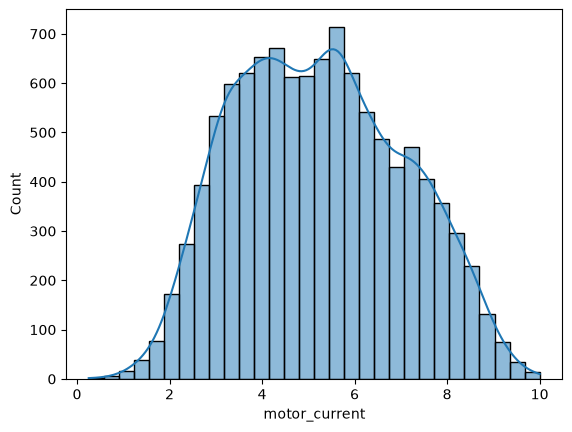

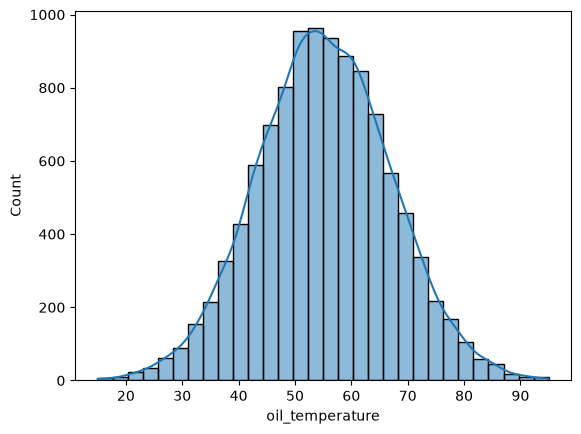

In [26]:
sns.histplot(readings["motor_current"], kde=True, bins=30)
plt.figure()
sns.histplot(readings["oil_temperature"], kde=True, bins=30)

### Alternatívna technika

Pre odstránenie outlierov sa dá použiť aj iná technika, kde vyberáme hodnoty na základe percentilu a tie ktoré sú mimo rozsahu nahradíme hraničnou hodnotou. Má výhodu že je viac automatická (nie je treba analyzovať rozdelenie aby sme zistili správne hranice) a zachová viac údajov v datasete. Na druhej strane to môže výrazne zmeniť rozdelenie a počet zasiahnutúch záznamov je väčší.

<Axes: xlabel='motor_current', ylabel='Count'>

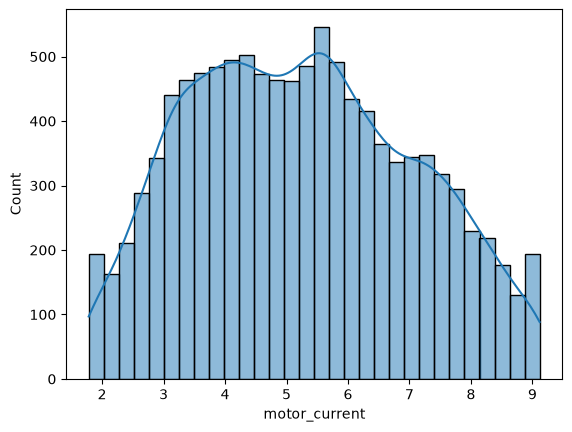

In [27]:
current = old_readings["motor_current"]

[lo, hi] = current.quantile([0.01, 0.99]).to_list()
old_readings["motor_current"] = current.clip(lo, hi)

sns.histplot(old_readings["motor_current"], kde=True, bins=30)

<Axes: xlabel='oil_temperature', ylabel='Count'>

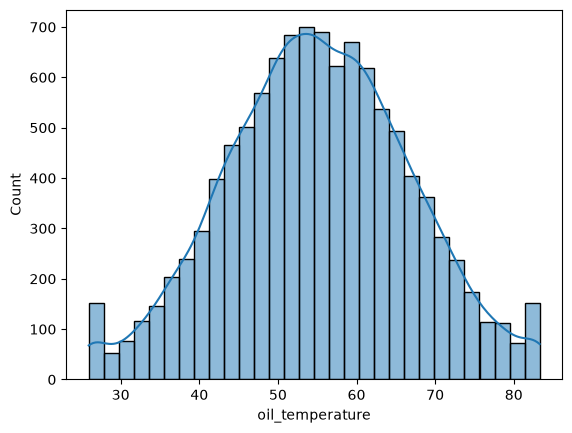

In [28]:
oil_temp = old_readings["oil_temperature"]

[lo, hi] = oil_temp.quantile([0.01, 0.99]).to_list()
old_readings["oil_temperature"] = oil_temp.clip(lo, hi)

sns.histplot(old_readings["oil_temperature"], kde=True, bins=30)

Vidíme že táto metóda vedie k výsledkom ktoré vyzerajú inak ako pri prvej technike. Na ľavej aj pravej strane histogramu je posledný stĺpec vyšší ako ten pred ním (bližšie k stredu), čo sa v pôvodných dátach nikdy nestalo a nereprezentuje skutočné rozdelenie prúdu alebo teploty. Preto **pokračujeme s prvým variantom** ktorý sme čistili odstránením extrémnych hodnôt.

## 1.1 B

Ako prvé potrebujeme zistiť čo ktorý atribút vlastne znamená. Veľkú časť z nich môžeme zistiť podľa názvu:

1. `unit_id`: ID vozidla
   
2. `cycle_timestamp`: Dátum merania
3. `motor_current`: Prúd motora APU v ampéroch - A
4. `filter_dp`: Diferenčný tlak na filtri - $\Delta p$
5. `oil_temperature`: Teplota mazacieho oleja - °C
6. `reservoir_pressure`: Tlak v hlavnom vzduchojeme - bar
7. `working_pressure`: Pracovný prevádzkový tlak - bar
8. `oil_pressure`: Tlak oleja v kompresore - bar
9.  `vibration_rms`: Efektívna hodnota vibrácií - RMS
10. `flow_meter`: Prietok stlačeného vzduchu
11. `humidity_intake` Relatívna vlhkosť nasávaného vzduchu - %
12. `ambient_noise` Hladina okolitého hluku - dB
13. `discharge_dewpoint` Rosný bod na výstupe sušiča - °C
14. `failure`: Cieľová binárna premenná: 0 = bez poruchy, 1 = porucha
    
16. `duty_class`: Trieda vozidla - ľahké (light), normálne (normal), ťažké (heavy)
17. `service_hours`: Prevádzkové hodiny vozidla
18. `model_code`: Model vozidla
    
19. `install_date`: Dátum inštalácie sieťového vybavenia

### Spojenie datasetu

Naše dáta sú rozdelené na 3 tabuľky - `readings`, `units` a `gateways`. Aby sa s nimi lepšie pracovalo, použijeme funkciu `merge` a spojíme ich do jednej tabuľky podľa `node_id`. Tak môžeme nájsť súvislosti medzi údajmi o vozidle ako `duty_class` a výsledkami merania zo senzorov.

In [29]:
data = pd.merge(readings, units, on="unit_id", how="left")
data.dropna(inplace=True)

data.info()
data.head()

<class 'pandas.DataFrame'>
Index: 10089 entries, 0 to 10738
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   unit_id             10089 non-null  int32   
 1   cycle_timestamp     10089 non-null  object  
 2   motor_current       10089 non-null  float64 
 3   filter_dp           10089 non-null  float64 
 4   oil_temperature     10089 non-null  float64 
 5   reservoir_pressure  10089 non-null  float64 
 6   working_pressure    10089 non-null  float64 
 7   oil_pressure        10089 non-null  float64 
 8   vibration_rms       10089 non-null  float64 
 9   flow_meter          10089 non-null  float64 
 10  humidity_intake     10089 non-null  float64 
 11  ambient_noise       10089 non-null  float64 
 12  discharge_dewpoint  10089 non-null  float64 
 13  aux_current         10089 non-null  float64 
 14  failure             10089 non-null  int64   
 15  depot_id            10089 non-null  float64 
 16  fl

,unit_id,cycle_timestamp,motor_current,filter_dp,oil_temperature,reservoir_pressure,working_pressure,oil_pressure,vibration_rms,flow_meter,...,ambient_noise,discharge_dewpoint,aux_current,failure,depot_id,fleet_code,duty_class,service_hours,install_region,model_code
0,256,2023-12-10,4.42042,20.58792,47.21276,9.23927,9.25717,3.96332,2.36210,32.31361,...,73.66297,5.84201,3.76478,0,34.0,FE,light,5272.9,Mirandela,APU-20
1,1652,2023-07-17,4.90300,28.52708,68.02586,8.29539,8.24885,3.81932,3.28220,23.63779,...,68.67375,6.69999,2.66410,0,113.0,FE,normal,9894.7,Vendas Novas,APU-12
2,529,2023-12-22,6.08280,20.98545,58.11114,8.95545,9.07570,3.39484,5.42669,26.31633,...,75.67641,11.91813,1.58497,0,86.0,FE,heavy,8892.7,New Jasonfort,APU-20
3,697,2023-01-29,6.69522,21.32718,70.81750,8.54513,8.56433,3.82058,7.90080,24.22535,...,64.90649,5.94331,4.15007,0,66.0,FD,normal,5062.0,Erkelenz,XC-7
4,1127,2023-06-14,6.35664,16.33700,52.16693,8.99387,8.73377,4.21274,2.18324,30.36919,...,77.78946,16.39197,2.65400,0,63.0,FC,normal,7083.5,Lestertown,APU-15


### Výber atribútov

Pre začiatok je dobre zistiť ktoré atribúty v datasete sú najdôležitejšie a ktoré môžeme naopak ignorovať. Na to máme niekoľko metód ako Variance Threshold, Mutual Information alebo ANOVA F-value. Pri analýze nepozeráme na `unit_id` a `depot_id`, pretože hodnota ID logicky nesúvisí s výsledkami merania a mohli by vzniknúť falošné korelácie.

(10089, 12) (10089,)
>Threshold=0.00, Features=12.00
>Threshold=0.05, Features=12.00
>Threshold=0.10, Features=12.00
>Threshold=0.15, Features=12.00
>Threshold=0.20, Features=12.00
>Threshold=0.25, Features=12.00
>Threshold=0.30, Features=12.00
>Threshold=0.35, Features=11.00
>Threshold=0.40, Features=9.00
>Threshold=0.45, Features=9.00
>Threshold=0.50, Features=9.00


[('humidity_intake', np.float64(601.8014368603338)),
 ('oil_temperature', np.float64(140.31928271038836)),
 ('filter_dp', np.float64(119.71207207404717)),
 ('ambient_noise', np.float64(37.374303277909334)),
 ('flow_meter', np.float64(16.261033160774204)),
 ('discharge_dewpoint', np.float64(12.231383772514512)),
 ('motor_current', np.float64(3.2871755252017953)),
 ('vibration_rms', np.float64(2.5142918050641496)),
 ('aux_current', np.float64(0.6965860688730935)),
 ('working_pressure', np.float64(0.3795593808563139)),
 ('reservoir_pressure', np.float64(0.3575335640322675)),
 ('oil_pressure', np.float64(0.31574205433965946))]

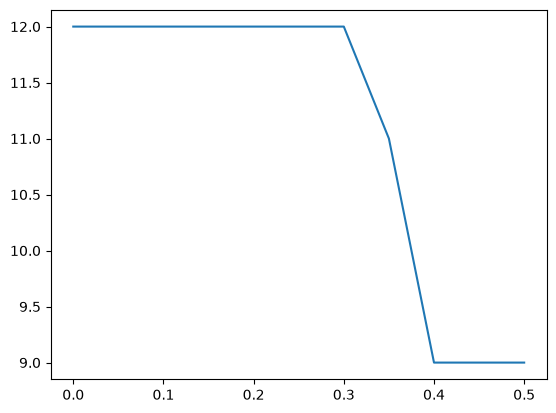

In [30]:
from sklearn.feature_selection import VarianceThreshold

numeric_fields = (
    data.select_dtypes(include=[np.number])
    .columns.drop(["unit_id", "depot_id"])
    .tolist()
)

df = data[numeric_fields]

vars = df.drop(["failure"], axis=1).values
X = vars[:, :-1]
y = vars[:, -1]
print(X.shape, y.shape)

thresholds = np.arange(0.0, 0.55, 0.05)
results = []
for t in thresholds:
    transform = VarianceThreshold(threshold=t)
    X_sel = transform.fit_transform(X)
    n_features = X_sel.shape[1]
    print(f">Threshold={t:.2f}, Features={n_features:.2f}")
    results.append(n_features)

plt.plot(thresholds, results)

sorted(
    zip(df.drop(["failure"], axis=1).columns, transform.variances_),
    key=lambda x: x[1],
    reverse=True,
)

Pri Variance Threshold vidíme že trvá dosť dlho kým sa začne znižovať počet premenných. To je vlastne dobrá správa, znamená to že náš dataset neobsahuje veľa zbytočných údajov.

service_hours         0.012081
filter_dp             0.005662
aux_current           0.004464
working_pressure      0.004032
discharge_dewpoint    0.003624
motor_current         0.003350
humidity_intake       0.002420
oil_temperature       0.001819
vibration_rms         0.001589
reservoir_pressure    0.000819
flow_meter            0.000325
ambient_noise         0.000000
oil_pressure          0.000000
dtype: float64


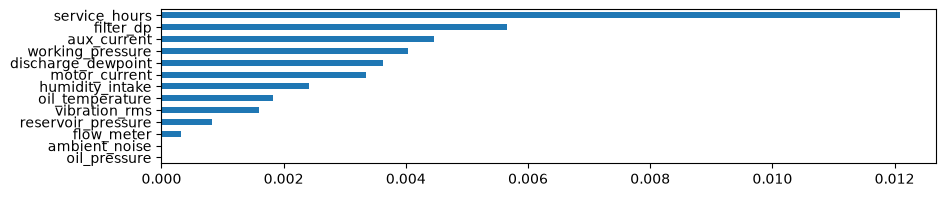

In [31]:
from sklearn.feature_selection import mutual_info_classif


def mic(X, y):
    selector = mutual_info_classif(X, y)
    scores = pd.Series(selector, index=X.columns).sort_values()

    plt.figure(figsize=(10, 2))
    scores.plot(kind="barh")
    print(scores.sort_values(ascending=False))


mic(df.drop("failure", axis=1), df["failure"])

Mutual Information hodnotí atribúty podľa toho ako dobre predpovedajú hodnotu Failure. Vidíme že najlepšie z toho vychádza `filter_dp` a `motor_current`, zatiaľ čo `oil_pressure` a `ambient_noise` sú nezávislé od Failure a nedávajú nám užitočné informácie.

In [32]:
from sklearn.feature_selection import SelectKBest, f_regression

X = df.drop("failure", axis=1)
y = df["failure"]

fs = SelectKBest(score_func=f_regression, k=10)
fs.fit_transform(X, y)

sorted(zip(X.columns, fs.scores_), key=lambda x: x[1], reverse=True)

[('filter_dp', np.float64(139.72497681242956)),
 ('service_hours', np.float64(139.66803196963164)),
 ('discharge_dewpoint', np.float64(41.36413952363725)),
 ('aux_current', np.float64(27.926855117751593)),
 ('motor_current', np.float64(24.55632460143304)),
 ('reservoir_pressure', np.float64(21.868603118384762)),
 ('working_pressure', np.float64(19.714639921199844)),
 ('oil_pressure', np.float64(16.89031730970748)),
 ('flow_meter', np.float64(4.812137527153437)),
 ('vibration_rms', np.float64(3.360991520879056)),
 ('ambient_noise', np.float64(0.2288538385166913)),
 ('humidity_intake', np.float64(0.19140407587427152)),
 ('oil_temperature', np.float64(0.1245695451292514))]

ANOVA F-value analýza dáva podobné výsledky aj keď presné poradie je iné. Najlepšie vychádzajú premenné `discharge_dewpoint`, `filter_dp` a `motor_current`. Sú to presne tie ktoré očakávame pretože ukazujú na rôzne problémy s motorom - zlé spaľovanie, pokazený filter a elektrický skrat.

In [33]:
def detailed_stats(df, columns):
    stats_list = []
    for col in columns:
        s = df[col].dropna()
        q25, q75 = s.quantile(0.25), s.quantile(0.75)
        iqr = q75 - q25
        stats_list.append(
            {
                "Atribút": col,
                "Počet (valid)": len(s),
                "Chýbajúce": df[col].isna().sum(),
                "Priemer": s.mean(),
                "Std": s.std(),
                "Medián": s.median(),
                "IQR": iqr,
                "Min": s.min(),
                "Max": s.max(),
            }
        )
    return pd.DataFrame(stats_list)


stats_sensors = detailed_stats(df, numeric_fields)
display(stats_sensors)

,Atribút,Počet (valid),Chýbajúce,Priemer,Std,Medián,IQR,Min,Max
0,motor_current,10089,0,5.240518,1.813147,5.17630,2.80574,0.25317,10.00000
1,filter_dp,10089,0,23.780538,10.941843,21.17820,12.32056,7.58265,118.17240
2,oil_temperature,10089,0,55.188510,11.846231,55.08473,15.91952,15.00000,95.00000
3,reservoir_pressure,10089,0,8.704151,0.597971,8.71057,0.79807,6.50000,10.50000
4,working_pressure,10089,0,8.704822,0.616114,8.70510,0.82076,6.46430,10.50000
5,oil_pressure,10089,0,3.698539,0.561937,3.70138,0.75542,1.70227,5.80497
6,vibration_rms,10089,0,3.053337,1.585730,2.70718,1.85847,0.50000,14.00000
7,flow_meter,10089,0,28.013528,4.032697,28.01460,5.38465,15.00000,40.00000
8,humidity_intake,10089,0,52.880754,24.532857,52.91293,42.40405,10.01358,94.99531
9,ambient_noise,10089,0,75.028419,6.113756,75.02362,8.27824,55.00000,95.00000


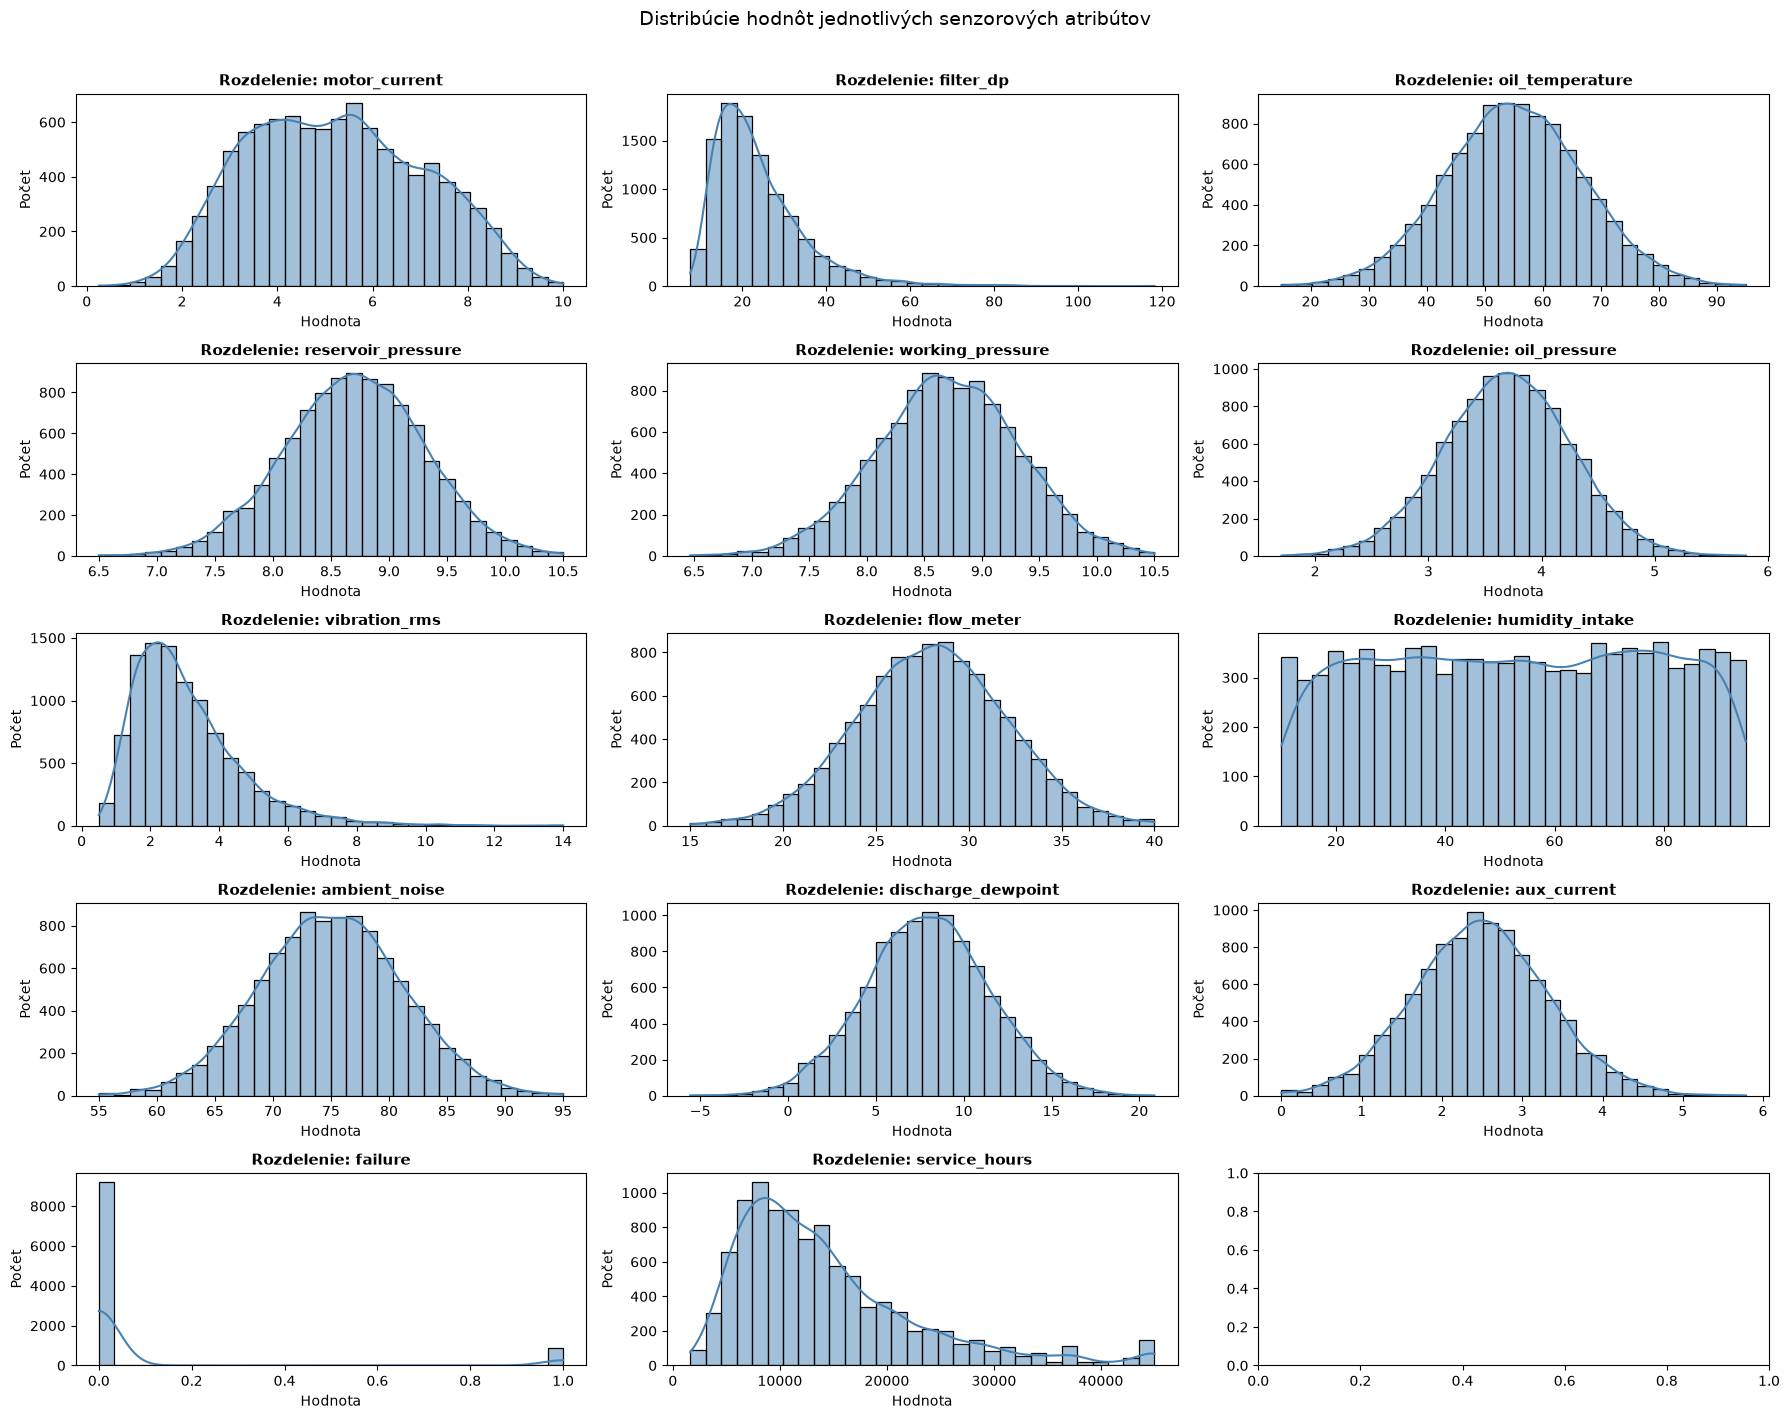

In [34]:
fig, axes = plt.subplots(5, 3, figsize=(18, 14))
axes = axes.flatten()

for idx, col in enumerate(numeric_fields):
    sns.histplot(data[col].dropna(), kde=True, ax=axes[idx], color="steelblue", bins=30)
    axes[idx].set_title(f"Rozdelenie: {col}", fontsize=11, fontweight="bold")
    axes[idx].set_xlabel("Hodnota")
    axes[idx].set_ylabel("Počet")

plt.suptitle(
    "Distribúcie hodnôt jednotlivých senzorových atribútov", fontsize=14, y=1.01
)
plt.tight_layout(h_pad=1.0)
plt.show()

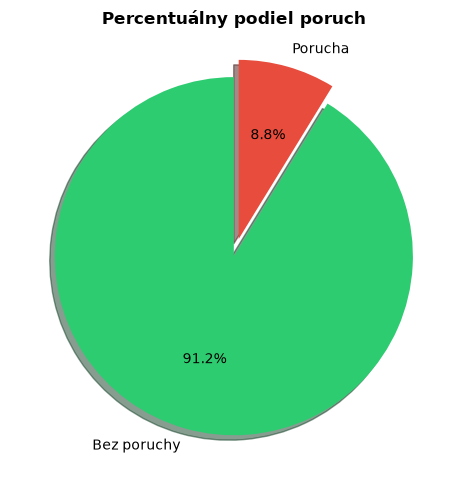

Cieľová premenná Failure: 9205 normálnych záznamov vs 884 porúch.
Pomer porúch v datasete je 8.76% .


In [35]:
failure_counts = data["failure"].value_counts()
failure_percentages = data["failure"].value_counts(normalize=True) * 100

fig, axe = plt.subplots(1, 1, figsize=(13, 5))

axe.pie(
    failure_counts,
    labels=["Bez poruchy", "Porucha"],
    autopct="%1.1f%%",
    colors=["#2ecc71", "#e74c3c"],
    startangle=90,
    explode=[0, 0.1],
    shadow=True,
)
axe.set_title("Percentuálny podiel poruch", fontweight="bold")

plt.tight_layout()
plt.show()

print(
    f"Cieľová premenná Failure: {failure_counts[0]} normálnych záznamov vs {failure_counts[1]} porúch."
)
print(f"Pomer porúch v datasete je {failure_percentages[1]:.2f}% .")

### 1.1 C

V tejto časti preskúmame lineárne aj nelineárne korelácie medzi jednotlivými prediktormi, aby sme identifikovali multikolinearitu, funkčné väzby a redundanciu v dátach.

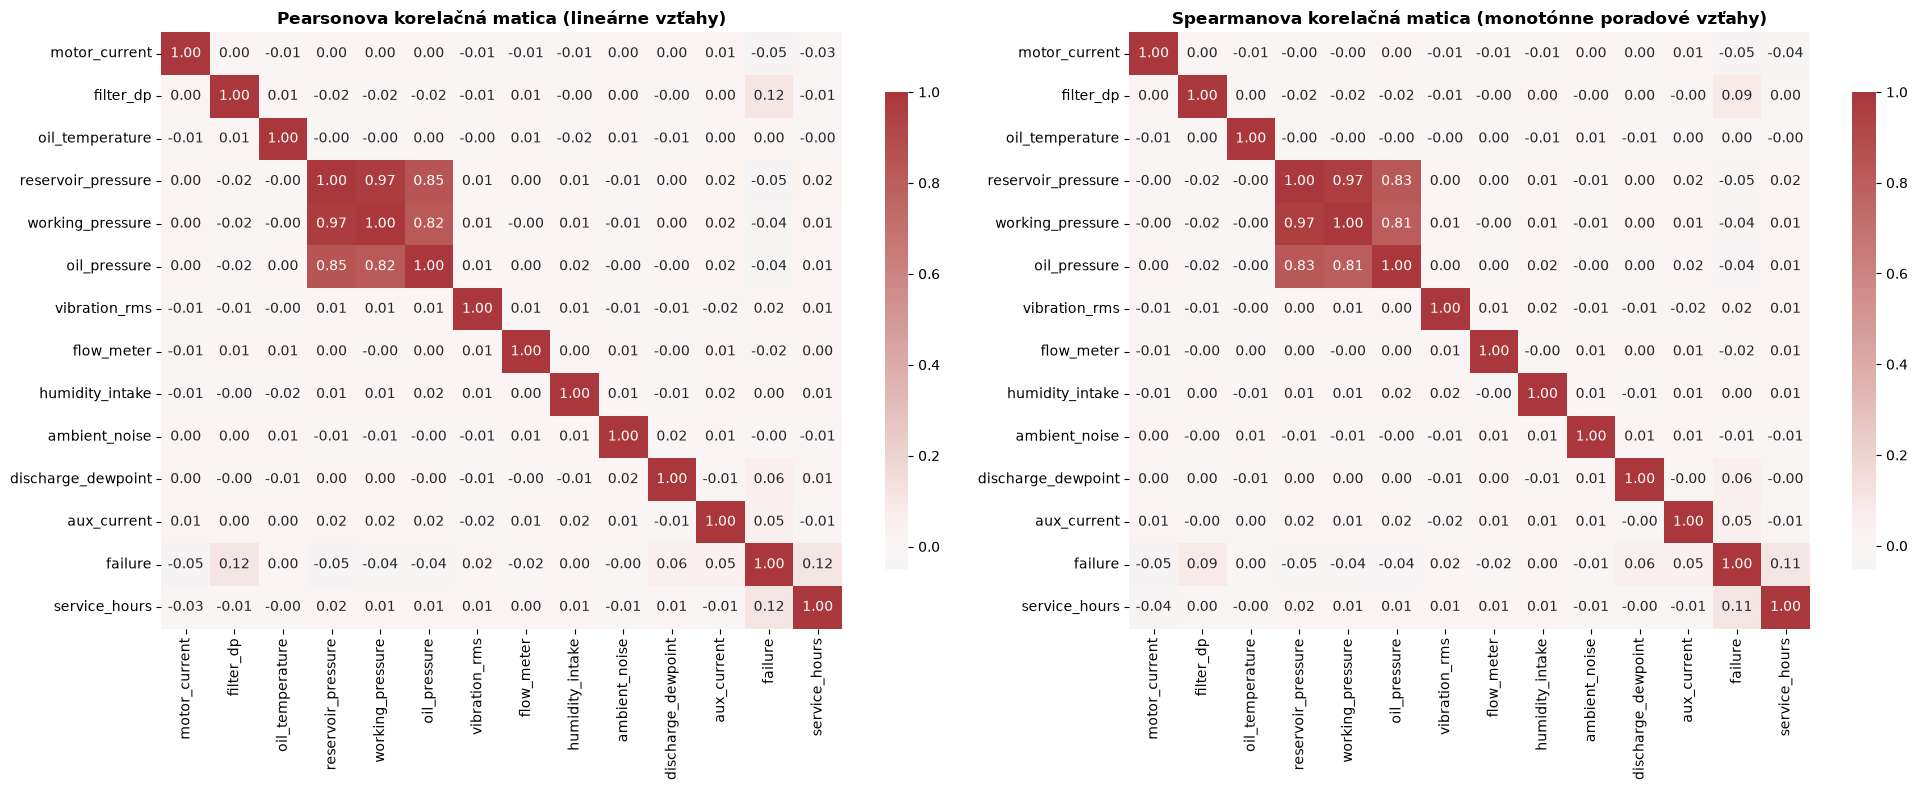

In [36]:
pearson_corr = data[numeric_fields].corr(method="pearson")
spearman_corr = data[numeric_fields].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    ax=axes[0],
    cbar_kws={"shrink": 0.8},
)
axes[0].set_title(
    "Pearsonova korelačná matica (lineárne vzťahy)", fontsize=12, fontweight="bold"
)

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    ax=axes[1],
    cbar_kws={"shrink": 0.8},
)
axes[1].set_title(
    "Spearmanova korelačná matica (monotónne poradové vzťahy)",
    fontsize=12,
    fontweight="bold",
)

plt.tight_layout()
plt.show()

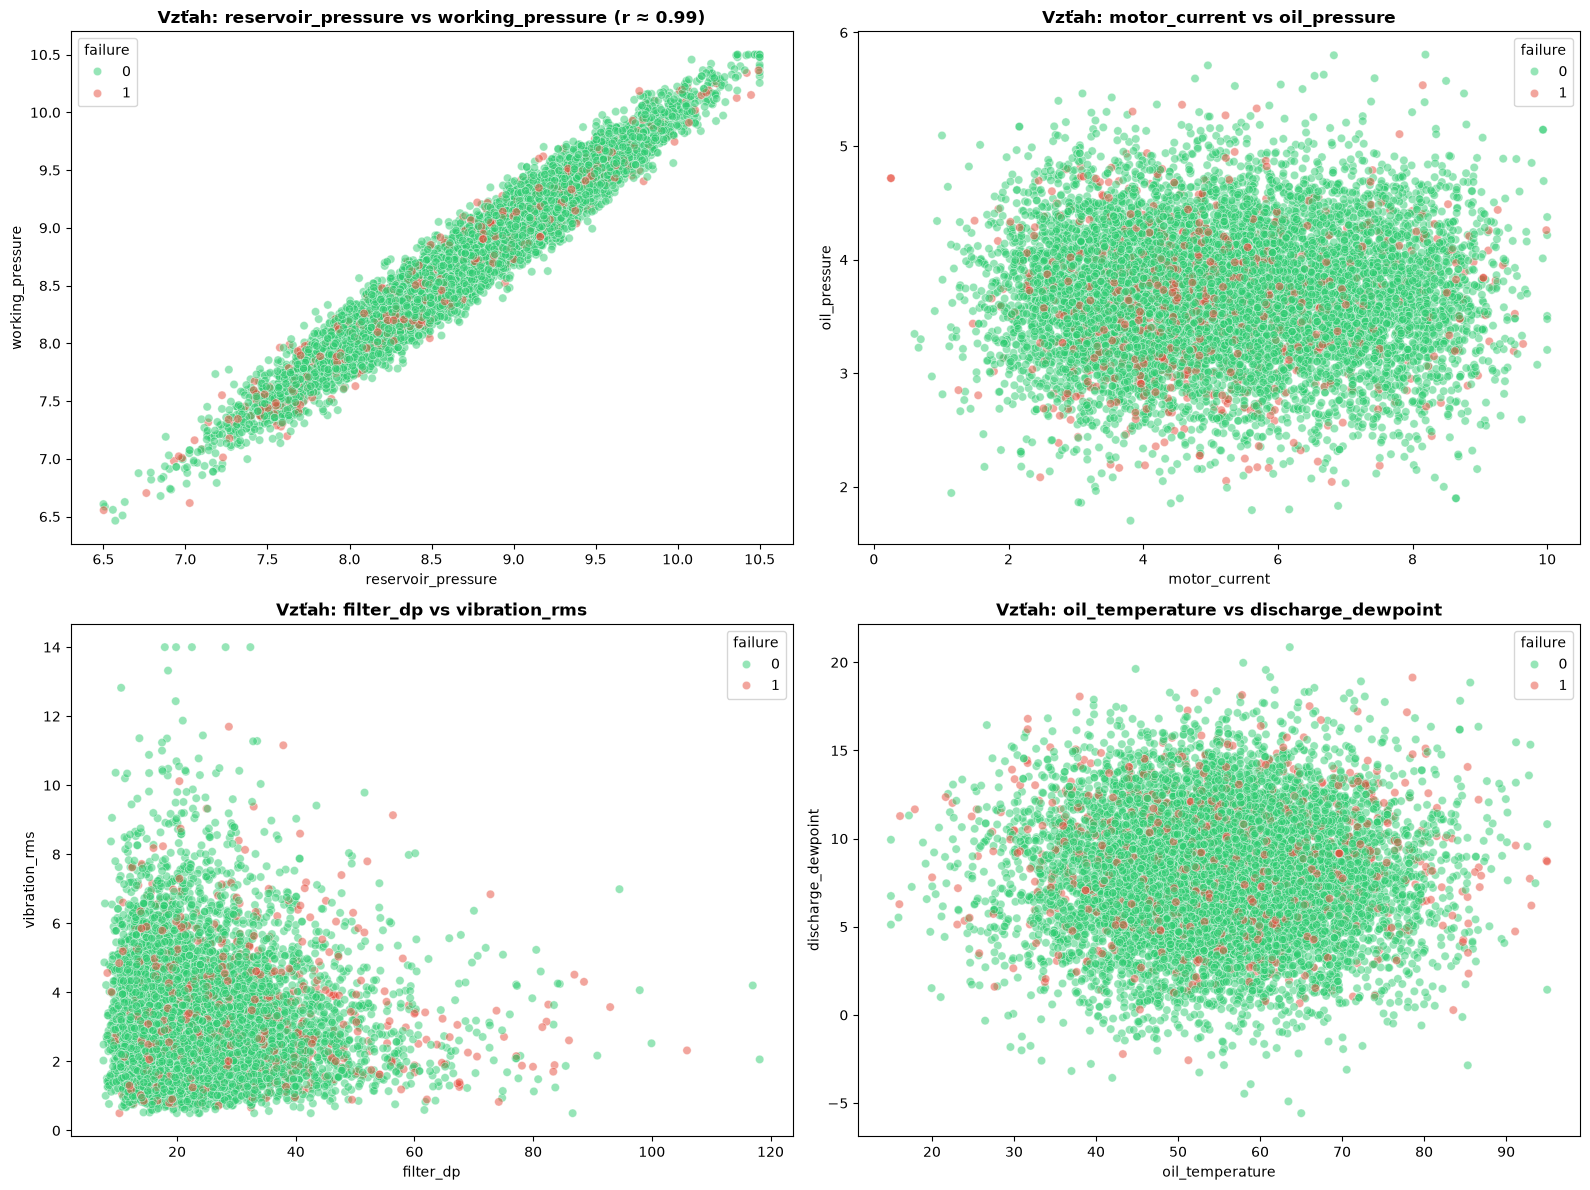

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))


sns.scatterplot(
    data=data,
    x="reservoir_pressure",
    y="working_pressure",
    hue="failure",
    palette=["#2ecc71", "#e74c3c"],
    alpha=0.5,
    ax=axes[0, 0],
)
axes[0, 0].set_title(
    "Vzťah: reservoir_pressure vs working_pressure (r ≈ 0.99)", fontweight="bold"
)

sns.scatterplot(
    data=data,
    x="motor_current",
    y="oil_pressure",
    hue="failure",
    palette=["#2ecc71", "#e74c3c"],
    alpha=0.5,
    ax=axes[0, 1],
)
axes[0, 1].set_title("Vzťah: motor_current vs oil_pressure", fontweight="bold")

sns.scatterplot(
    data=data,
    x="filter_dp",
    y="vibration_rms",
    hue="failure",
    palette=["#2ecc71", "#e74c3c"],
    alpha=0.5,
    ax=axes[1, 0],
)
axes[1, 0].set_title("Vzťah: filter_dp vs vibration_rms", fontweight="bold")

sns.scatterplot(
    data=data,
    x="oil_temperature",
    y="discharge_dewpoint",
    hue="failure",
    palette=["#2ecc71", "#e74c3c"],
    alpha=0.5,
    ax=axes[1, 1],
)
axes[1, 1].set_title("Vzťah: oil_temperature vs discharge_dewpoint", fontweight="bold")

plt.tight_layout()
plt.show()

### 1.1 D

V tejto časti identifikujeme, ktoré senzory a vlastnosti kompresorových jednotiek sa najvýraznejšie menia pri vzniku poruchy.

/tmp/ipykernel_439664/2793207260.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=corr_with_failure.values, y=corr_with_failure.index, palette=colors)


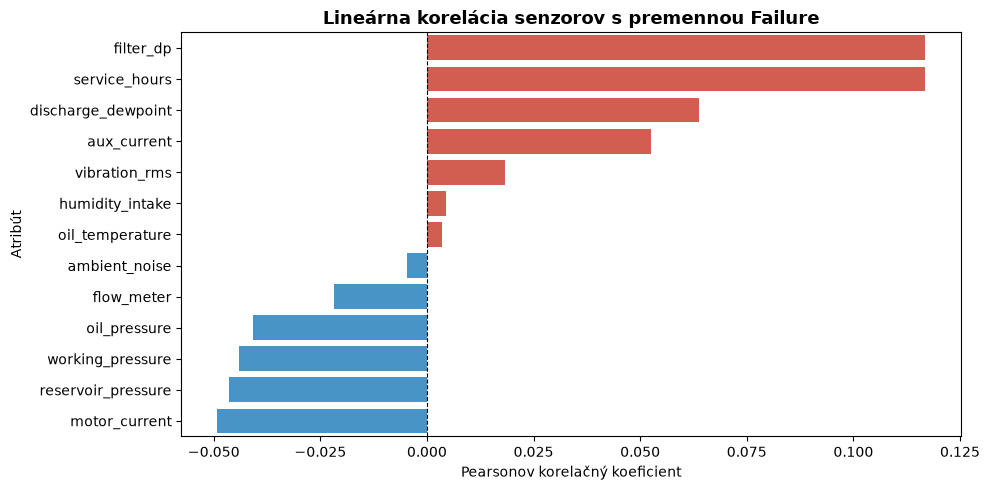

Rebríček korelácie s poruchou (Failure):


,Korelácia s Failure
filter_dp,0.116888
service_hours,0.116864
discharge_dewpoint,0.063906
aux_current,0.052545
vibration_rms,0.018251
humidity_intake,0.004356
oil_temperature,0.003514
ambient_noise,-0.004763
flow_meter,-0.021837
oil_pressure,-0.040886


In [38]:
# Korelácia všetkých numerických premenných s Failure
corr_with_failure = (
    data[numeric_fields].corr()["failure"].drop("failure").sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
colors = ["#e74c3c" if x > 0 else "#3498db" for x in corr_with_failure.values]
sns.barplot(x=corr_with_failure.values, y=corr_with_failure.index, palette=colors)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.title(
    "Lineárna korelácia senzorov s premennou Failure", fontsize=13, fontweight="bold"
)
plt.xlabel("Pearsonov korelačný koeficient")
plt.ylabel("Atribút")
plt.tight_layout()
plt.show()

print("Rebríček korelácie s poruchou (Failure):")
display(corr_with_failure.to_frame(name="Korelácia s Failure"))

### 1.1 E

* Silná kolinearita: `reservoir_pressure` a `working_pressure` majú koreláciu $r = 0.97$. V modelovaní postačí jeden z nich.

* Kľúčové prediktory zlyhania sú diferenčný tlak na filtri (`filter_dp`), rosný bod výstupu (`discharge_dewpoint`), pomocný prúd (`aux_current`), pokles pracovného tlaku (`oil_pressure`, `reservoir_pressure`) a zvýšené vibrácie (`vibration_ms`).

# 1.3 Formulácia hypotéz o dátach

Na základe výsledkov EDA a logických súvislostí medzi premennými formulujeme dve hypotézy. Používame atribúty pri ktorých všetky techniky výberu vrátili vysoké hodnoty a je veľká šanca že budú mať výrazný vplyv na `failure`.

1. Hodnota `service_hours` je v priemere vyššia v stave s `failure` ako bez nej. Vysvetlenie: staršie jednotky sú viac opotrebované a tak je u nich vyššia pravdepodobnosť že majú skryté problémy, ktoré sa neskôr prejavia ako úplné zlyhanie.
2. Hodnota `motor_current` je v priemere nižšia v stave s `failure` ako bez nej. Ak je elektrický prúd pod normálnou hodnotou, ukazuje to na možný skrat alebo slabé prepojenie jednotlivých komponentov. To ďalej vedie k zastaveniu motora, informačného systému alebo riadenia vozidla.

### Testovanie hypotéz

V prvom prípade chceme zistiť, či je štatisticky významný rozdiel medzi priemernou hodnotou `service_hours` v záznamoch s `failure` a tými bez nej. Naše hypotézy sú:

- Nulová $H_0$ - medzi skupinami nie je rozdiel, priemer `service_hours` je rovnaký pre obe skupiny
- Testovaná $H_1$ - priemer `service_hours` je iný v skupine s `failure` a skupine bez `failure`

Pre pozitívny výsledok musíme dokázať, že vhodný štatistický test vracia hodnotu $p$ menšiu ako 0.05. To znamená že ak v skutočnosti platí $H_0$, pravdepodobnosť že by sme pri náhodnej vzorke záznamov videli podobne veľký rozdiel v priemere oboch skupín je menšia ako 5 percent. Podľa štandardných postupov tak môžeme nulovú hypotézu odmietnuť ako nepravdepodobnú.

Na začiatok porovnáme rozdelenie každej skupiny. Skupina s `failure` má viac prvkov, preto v kóde používame `stat=density` a porovnávame hustotu namiesto absolútneho počtu prvkov pre každý bin.

<Axes: xlabel='service_hours', ylabel='Density'>

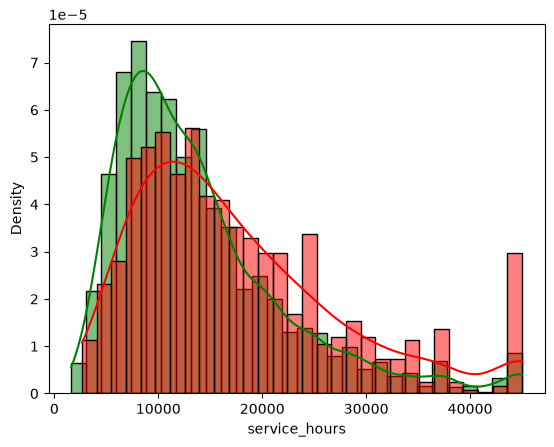

In [39]:
good = data[data["failure"] == 0]["service_hours"]
failed = data[data["failure"] == 1]["service_hours"]

sns.histplot(
    good, kde=True, color="green", label="Bez poruchy", bins=30, stat="density"
)
sns.histplot(failed, kde=True, color="red", label="Porucha", bins=30, stat="density")

Medzi skupinami je viditeľný rozdiel - červená (failure=1) je oproti zelenej posunutá doprava, má na pravej strane viac outlierov, hodnoty sú menej koncentrované okolo najvyššieho vrcholu. Každý z týchto efektov je individuálne malý ale spolu menia rozdelenie rovnakým smerom. Na grafe KDE (súvislá čiara) vidíme že v skupine so zlyhaním je pomerne viac hodnôt `service_hours` nad 15 000 a menej pod 15 000.

Z histogramu vidíme aj to že rozdelenie tejto premennej nevyzerá ako normálne. Aby sme to potvrdili vykonáme Shapiro-Wilk test normality:

In [40]:
from scipy.stats import shapiro

print(shapiro(good))
print(shapiro(failed))

ShapiroResult(statistic=np.float64(0.8764922540501825), pvalue=np.float64(7.994781462596684e-65))
ShapiroResult(statistic=np.float64(0.907648616007639), pvalue=np.float64(1.0354653386373383e-22))


/home/jastcher/School/IAU/iau-new/.venv/lib/python3.14/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 9205.
  res = hypotest_fun_out(*samples, **kwds)


Výsledná p-value je pre jednu skupinu približne $2.9\cdot10^{-30}$ a pre druhú $2.4\cdot10^{-10}$, čo je výrazne menej ako 0.05. V tomto prípade sme testovali a odmietli nulovú hypotézu že hodnoty sú normálne rozdelené, preto pokračujeme s tým že rozdelenie **nie je normálne**. To znamená že nemôžeme použiť štandardné parametrické testy ako Student's t. Na testovanie pôvodnej $H_0$ a $H_1$ tak použijeme alternatívny **Mann-Whitney U** test, ktorý má menšiu štatistickú silu ale je vhodný pre iné ako normálne distrubúcie.

In [41]:
from scipy.stats import mannwhitneyu

stat, p = mannwhitneyu(good, failed)
print(f"U = {stat:.3f}, p={p}")

U = 3146844.000, p=7.688725488950159e-29


Výsledok testu je jednoznačný. Hodnota $p$ je okolo $7\cdot10^{-29}$ čo je menej ako 0.05, preto **odmietame $H_0$**. To znamená že priemer `service_hours` je pre každú skupinu rozdielny. Nevieme ale ktorým smerom - je pre meranie s `failure` vyšší alebo nižší? S tým nám pomôže zobrazenie v grafe.

<Axes: xlabel='failure', ylabel='service_hours'>

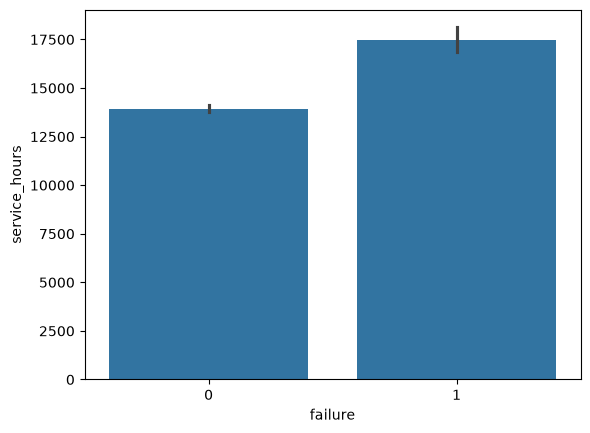

In [42]:
sns.barplot(x="failure", y="service_hours", data=data)

Vidíme že priemer `service_hours` je vyšší v skupine s failure. Spolu s výsledkom testu to znamená že naša pôvodná hypotéza podľa všetkého platí - dlhší čas v službe vedie k poruchám.

### Štatistická sila

Na to aby sme úplne verili vlastnej hypotéze, musíme overiť že má dostatočnú podporu v dátach a výsledok ktorý nám vyšiel nebol náhodný. Na to je najjednoduchšie použiť **95% confidence interval** ktorý už máme na predchádzajúcom grafe.

Intervaly na grafe sa neprekrývajú, čo znamená že test je dostatočne silný - je len malá šanca (menej ako 5 %) že priemer `service_hours` v skupine s `failure=1` je v skutočnosti rovnaký alebo menší ako v `failure=0`.

### Druhá hypotéza

V druhej časti úlohy testujeme aký je vzťah medzi premennými `failure` a `motor_current`. Definujeme hypotézy:

- $H_0$ - priemer `motor_current` je rovnaký pre obe skupiny
- $H_1$ - priemer `motor_current` je iný v skupine s `failure` a skupine bez `failure`

Cieľ testovania je ako predtým odmietnuť $H_0$ a tak dokázať že priemery sú iné.

<Axes: xlabel='motor_current', ylabel='Density'>

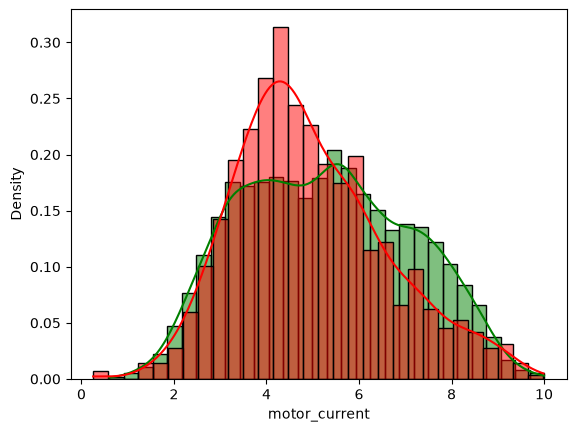

In [43]:
good = data[data["failure"] == 0]["motor_current"]
failed = data[data["failure"] == 1]["motor_current"]

sns.histplot(
    good, kde=True, color="green", label="Bez poruchy", bins=30, stat="density"
)
sns.histplot(failed, kde=True, color="red", label="Porucha", bins=30, stat="density")

V porovnaní s prvým prípadom je rozdiel medzi skupinami menší - majú rovnaký rozsah, ani jedna nemá outlierov a histogramy sa dosť prekrývajú. Hlavný rozdiel je v tom že červená skupina (failure=1) je viac koncentrovaná okolo jedného vrcholu na ľavej strane a zelená má plochý tvar s 3 vrcholmi.

Podobne ako v prvej úlohe skontrolujeme či sú rozdelenia normálne.

In [44]:
print(shapiro(good))
print(shapiro(failed))

ShapiroResult(statistic=np.float64(0.9847578942573698), pvalue=np.float64(2.8697660763542677e-30))
ShapiroResult(statistic=np.float64(0.9778112704258485), pvalue=np.float64(2.4120319780147986e-10))


/home/jastcher/School/IAU/iau-new/.venv/lib/python3.14/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 9205.
  res = hypotest_fun_out(*samples, **kwds)


Výsledok je malý pre obe skupiny a tak pokračujeme s tým že rozdelenia nie sú normálne. Preto znova použijeme U-test aby sme zistili či je rozdiel ich priemerov významný.

In [45]:
stat, p = mannwhitneyu(good, failed)
print(f"U = {stat:.3f}, p={p}")

U = 4492185.000, p=3.0426113730638303e-07


P-value je okolo $3\cdot10^{-7}$, viac ako v predošlej úlohe ale menej ako 0.05. Preto odmietame nulovú hypotézu - priemer `motor_current` je iný v skupine `failure=0` a `failure=1`.

Zostáva už len zistiť, ako veľký efekt to je a aký má smer.

<Axes: xlabel='failure', ylabel='motor_current'>

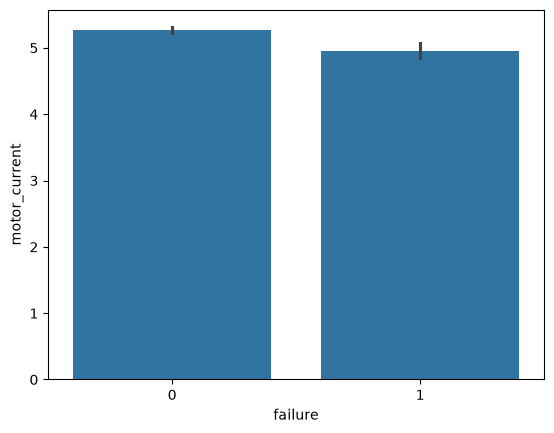

In [46]:
sns.barplot(x="failure", y="motor_current", data=data)

Rozdiel je relatívne malý, ale 95% CI sa neprekrývajú a tak môžeme povedať že je štatisticky významný. Priemer je nižší v skupine s `failure=1`. Tak sme **potvrdili pôvodnú hypotézu** - meraný prúd je v priemere menší v prípadoch keď registrujeme poruchu vozidla.

# 2. Predspracovanie údajov
Hugo Foltin - 50%, Teodor Potančok - 50%

## 2.1 Realizácia predspracovania dát

### 2.1 A Rozdelenie dát na trénovaciu a testovaciu množinu

Ako prvý krok rozdelíme náš dataset na dve časti aby sme sa vyhli kontaminácii a skreesleným výsledkom pri testovaní. Používame rozdelenie 20% test a 80% train, čo vychádza na približne 2 018 a 8 071 vzoriek.

Pri náhodnom rozdelení môže byť problém že pomer vzoriek v ktorých je `failure=0` a `failure=1` nebude v každej množine rovnaký. Preto používame stratifikáciu s parametrom `stratify=y`, ktorá zabezpečí že pomer bude identický.

Replikovateľnosť procesu zabezpečíme cez fixný seed náhodného generátora `seed = 20261023`, čo je dátum keď sme na tejto úlohe začali robiť.

Okrem toho musíme vyradiť nerelevantné stĺpce:
  - `unit_id`: Unikátny identifikátor konkrétneho vozidla. Ak tento atribút necháme v datasete, model začne memorovať kombinácie ID/failure z training setu a dostaneme overfiting.
  - `depot_id` a `install_region`: Údaje o mieste kde je vozidlo v prevádzke. Ak majú jednotlivé regióny rôzne podmienky (vlhkosť, kvalita údržby) model sa ich naučí a stratí schopnosť generalizácie.
  - `cycle_timestamp`: Dátum uložený v pôvodnom formáte ako text. Algoritmy zo scikit-learn nevedia spracovať iné ako numerické dáta, preto dátum konvertujeme na čísla a pôvodný atribút vyradíme.

In [47]:
from sklearn.model_selection import train_test_split

seed = 20261023

ts = pd.to_datetime(data["cycle_timestamp"], format="mixed")
data_ml = data.copy()
data_ml["cycle_month"] = ts.dt.month
data_ml["cycle_dayofweek"] = ts.dt.dayofweek

drop_cols = ["unit_id", "cycle_timestamp", "depot_id", "install_region"]
data_ml = data_ml.drop(columns=[c for c in drop_cols if c in data_ml.columns])

X = data_ml.drop(columns=["failure"])
y = data_ml["failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=seed, stratify=y
)

print(f"Celkový počet pozorovaní: {len(data_ml)}")
print(f"Trénovacia množina (X_train): {X_train.shape[0]} riadkov, {X_train.shape[1]} stĺpcov")
print(f"Testovacia množina  (X_test):  {X_test.shape[0]} riadkov, {X_test.shape[1]} stĺpcov")
print(f"Podiel porúch v trénovacej sade: {y_train.mean():.4f} ({y_train.sum()} porúch)")
print(f"Podiel porúch v testovacej sade:  {y_test.mean():.4f} ({y_test.sum()} porúch)")


Celkový počet pozorovaní: 10089
Trénovacia množina (X_train): 8071 riadkov, 18 stĺpcov
Testovacia množina  (X_test):  2018 riadkov, 18 stĺpcov
Podiel porúch v trénovacej sade: 0.0876 (707 porúch)
Podiel porúch v testovacej sade:  0.0877 (177 porúch)


### 2.1 B Transformácia dát na numerický formát pre ML a integrácia čistenia

Knižnica scikit-learn čaká že všetky údaje sú v numerickom formáte, v datasete nie sú chýbajúce hodnoty (NA) a jeden riadok opisuje jedno pozorovanie. Všetky podmienky už máme splnené po fáze 1 ale môžeme to pre istotu overiť.

V našom datasete by malo byť:
- 15 spojitých atribútov:
   - Merania zo senzorov: `motor_current`, `filter_dp`, `oil_temperature`, `reservoir_pressure`, `working_pressure`, `oil_pressure`, `vibration_rms`, `flow_meter`, `humidity_intake`, `ambient_noise`, `discharge_dewpoint`, `aux_current`
   - Prevádzkové hodiny: `service_hours`
   - Časové príznaky: `cycle_month`, `cycle_dayofweek`
- 3 Kategorické atribúty:
   - `duty_class`: prevádzková trieda zaťaženia (`light`, `normal`, `heavy`).
   - `fleet_code`: kód flotily (`FA`, `FB`, `FC`, `FD`, `FE`).
   - `model_code`: kód modelu APU (`APU-10`, `APU-12`, `APU-15`, `APU-20`).

In [48]:
numeric_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X_train.select_dtypes(include=["str", "category", "object"]).columns.tolist()

print("Zoznam numerických atribútov (", len(numeric_cols), "):")
print(numeric_cols)
print("\nZoznam kategorických atribútov (", len(categorical_cols), "):")
print(categorical_cols)

print("\nKontrola chýbajúcich hodnôt (NaN):")
print(f" - Chýbajúce hodnoty v X_train: {X_train.isna().sum().sum()}")
print(f" - Chýbajúce hodnoty v X_test:  {X_test.isna().sum().sum()}")


Zoznam numerických atribútov ( 15 ):
['motor_current', 'filter_dp', 'oil_temperature', 'reservoir_pressure', 'working_pressure', 'oil_pressure', 'vibration_rms', 'flow_meter', 'humidity_intake', 'ambient_noise', 'discharge_dewpoint', 'aux_current', 'service_hours', 'cycle_month', 'cycle_dayofweek']

Zoznam kategorických atribútov ( 3 ):
['fleet_code', 'duty_class', 'model_code']

Kontrola chýbajúcich hodnôt (NaN):
 - Chýbajúce hodnoty v X_train: 0
 - Chýbajúce hodnoty v X_test:  0


### 2.1 C Transformácia atribútov (Scaling a Transformers)

Podľa zadania testujeme:
- 3 scaling techniky:
  1. `StandardScaler` – z-score štandardizácia, výsledok je priemer 0 a rozptyl 1
  2. `RobustScaler` – škálovanie založené na mediáne, menej citlivé na outlierov
  3. `MinMaxScaler` – lineárna normalizácia do interevalu [0, 1].
- 2 techniky transformácie rozdelenia:
  1. `PowerTransformer` (metóda Yeo-Johnson)
  2. `QuantileTransformer` (mapovanie na normálne rozdelenie)

Pre každú transformáciu porovnáme zmenu šikmosti (skewness), priemeru, smerodajnej odchýlky, minima a maxima. Tak zistíme aký majú efekt na rozdelenie jednotlivých atribútov.

In [49]:
from sklearn.preprocessing import (
    MinMaxScaler,
    PowerTransformer,
    QuantileTransformer,
    RobustScaler,
    StandardScaler,
)

sample_cols = ["service_hours", "filter_dp", "motor_current", "working_pressure"]

scalers_dict = {
    "Pôvodné (Raw)": None,
    "StandardScaler": StandardScaler(),
    "RobustScaler": RobustScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "PowerTransformer (Yeo-Johnson)": PowerTransformer(method="yeo-johnson"),
    "QuantileTransformer (Normal)": QuantileTransformer(output_distribution="normal", random_state=seed),
}

stats_records = []
for col in sample_cols:
    raw_vals = X_train[[col]].values
    for s_name, s_obj in scalers_dict.items():
        if s_obj is None:
            t_vals = raw_vals.flatten()
        else:
            t_vals = s_obj.fit_transform(raw_vals).flatten()
            
        stats_records.append({
            "Atribút": col,
            "Transformácia": s_name,
            "Šikmosť (Skewness)": round(float(pd.Series(t_vals).skew()), 3),
            "Priemer": round(float(np.mean(t_vals)), 3),
            "Smer. odchýlka": round(float(np.std(t_vals)), 3),
            "Min": round(float(np.min(t_vals)), 3),
            "Max": round(float(np.max(t_vals)), 3),
        })

df_transform_stats = pd.DataFrame(stats_records)
display(df_transform_stats)


,Atribút,Transformácia,Šikmosť (Skewness),Priemer,Smer. odchýlka,Min,Max
0,service_hours,Pôvodné (Raw),1.420,14235.377,8555.482,1617.000,45000.000
1,service_hours,StandardScaler,1.420,-0.000,1.000,-1.475,3.596
2,service_hours,RobustScaler,1.420,0.214,0.878,-1.081,3.371
3,service_hours,MinMaxScaler,1.420,0.291,0.197,0.000,1.000
4,service_hours,PowerTransformer (Yeo-Johnson),-0.001,0.000,1.000,-3.410,2.311
5,service_hours,QuantileTransformer (Normal),0.967,0.033,1.135,-5.199,5.199
6,filter_dp,Pôvodné (Raw),1.837,23.830,10.940,7.583,117.007
7,filter_dp,StandardScaler,1.837,-0.000,1.000,-1.485,8.517
8,filter_dp,RobustScaler,1.837,0.214,0.888,-1.105,7.780
9,filter_dp,MinMaxScaler,1.837,0.148,0.100,0.000,1.000


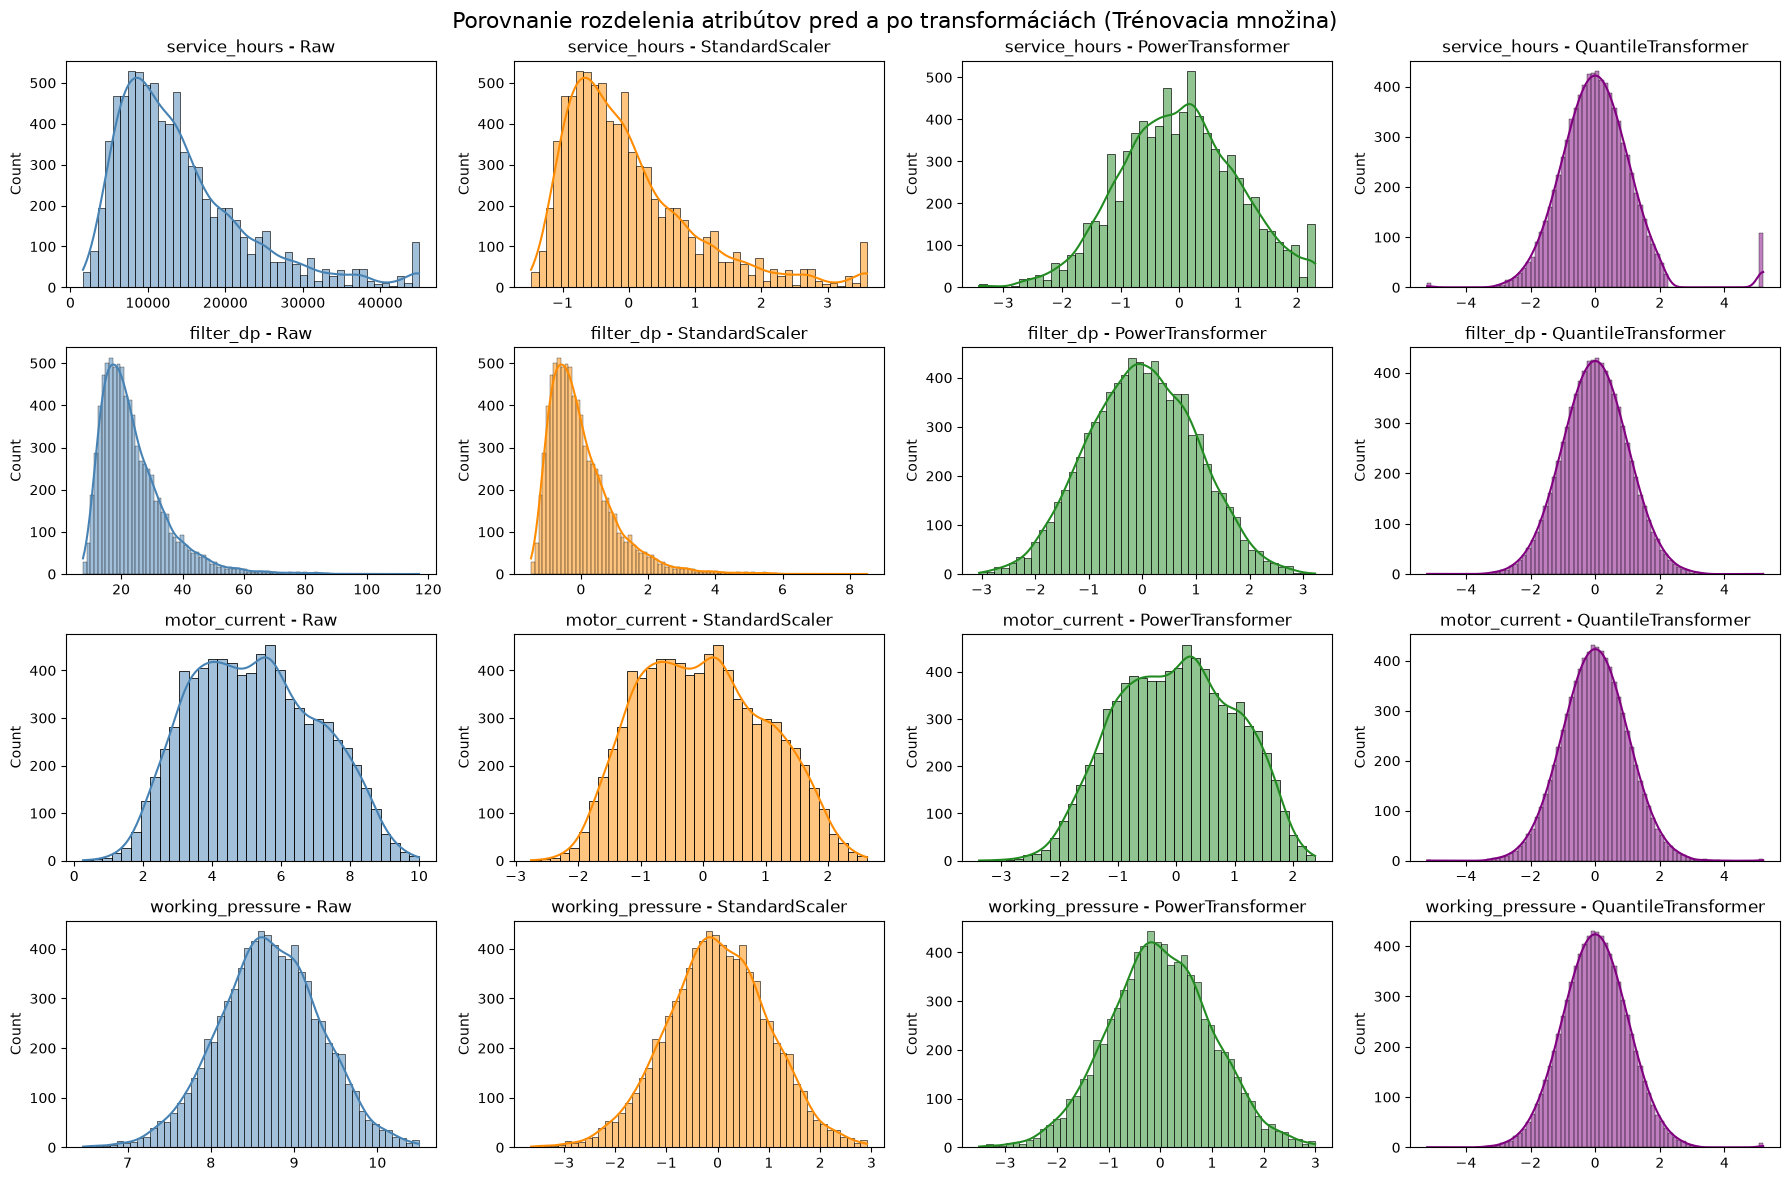

In [50]:
fig, axes = plt.subplots(len(sample_cols), 4, figsize=(18, 12))
fig.suptitle("Porovnanie rozdelenia atribútov pred a po transformáciách (Trénovacia množina)", fontsize=16)

for i, col in enumerate(sample_cols):
    raw_vals = X_train[[col]].values
    
    sns.histplot(raw_vals.flatten(), kde=True, ax=axes[i, 0], color="steelblue")
    axes[i, 0].set_title(f"{col} - Raw")
    
    ss_vals = StandardScaler().fit_transform(raw_vals).flatten()
    sns.histplot(ss_vals, kde=True, ax=axes[i, 1], color="darkorange")
    axes[i, 1].set_title(f"{col} - StandardScaler")
    
    pt_vals = PowerTransformer(method="yeo-johnson").fit_transform(raw_vals).flatten()
    sns.histplot(pt_vals, kde=True, ax=axes[i, 2], color="forestgreen")
    axes[i, 2].set_title(f"{col} - PowerTransformer")
    
    qt_vals = QuantileTransformer(output_distribution="normal", random_state=seed).fit_transform(raw_vals).flatten()
    sns.histplot(qt_vals, kde=True, ax=axes[i, 3], color="purple")
    axes[i, 3].set_title(f"{col} - QuantileTransformer")

plt.tight_layout()
plt.show()


### 2.1 D Zdôvodnenie volieb pre predspracovanie dát

Pre ďalšie spracovanie vyberáme kombináciu `RobustScaler` a `QuantileTransformer`, ktorá v testoch priniesla najlepšie výsledky. Potrebujeme jeden aj druhý - scaler vyrovná priemerenú veľkosť medzi premennými ale nemení distribúciu v rámci každej z nich.

Po spracovaní sa dostala šikmosť `service_hours` z hodnoty 1.456 na -0.001 a `filter_dp` z 1.865 na 0.016, čo znamená že sú výrazne viac symetrické ako predtým. To nám pomôže pri trénovaní modelov ako Naive Bayes alebo logistická regresia ktoré potrebujú mať rozdelenie čo najbližšie k normálnemu.

## 2.2 Výber atribútov pre strojové učenie

### 2.2 A Informatívnosť atribútov (3 techniky)

Aby sme zistili ktoré atribúty sú pre strojové učenie dôležité, porovnáme ich vzťah s predikovanou `failure` 3 rôznymi metódami:

- Mutual Information (`mutual_info_classif`) porovnáva atribúty s `failure` na základe informačnej teórie - ako dobre vieme predpovedať jednu hodnotu keď poznáme druhú.

- ANOVA F-test (`f_classif`) meria rozdiel medzi priemernou hodnotou premennej v skupine s `failure=0` a `failure=1`. Veľký rozdiel znamená štatisticky významný efekt ktorý má podľa všetkého vplyv na pravdepodobnosť poruchy.

- Gini MDI trénuje Random Forest Classifier na všetkých atribútoch súčasne a meria dôležitosť každého z nich na základe metódy Mean Decrease in Impurity. Dokáže nájsť komplexné vzťahy v ktorých majú vplyv viac ako dva atribúty.

Pre každý atribút vypočítame dôležitosť pomocou všetkých metód. Na výber použijeme priemer výsledkov každej z nich.

In [51]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import f_classif
from sklearn.preprocessing import OrdinalEncoder

# MDI potrebuje numerické dáta
ord_enc = OrdinalEncoder()
X_train_enc = X_train.copy()
X_train_enc[categorical_cols] = ord_enc.fit_transform(X_train[categorical_cols])

mi_scores = mutual_info_classif(X_train_enc, y_train, random_state=seed)

f_scores, p_scores = f_classif(X_train_enc, y_train)
f_scores = np.nan_to_num(f_scores, nan=0.0)

rf_fs = RandomForestClassifier(n_estimators=100, random_state=seed, class_weight="balanced")
rf_fs.fit(X_train_enc, y_train)
rf_scores = rf_fs.feature_importances_

df_fs = pd.DataFrame({
    "Atribút": X_train.columns,
    "Mutual_Information": mi_scores,
    "ANOVA_F_Score": f_scores,
    "RF_Importance": rf_scores,
})

df_fs["MI_Rank"] = df_fs["Mutual_Information"].rank(ascending=False)
df_fs["ANOVA_Rank"] = df_fs["ANOVA_F_Score"].rank(ascending=False)
df_fs["RF_Rank"] = df_fs["RF_Importance"].rank(ascending=False)

df_fs["Average_Rank"] = df_fs[["MI_Rank", "ANOVA_Rank", "RF_Rank"]].mean(axis=1)
df_fs = df_fs.sort_values(by="Average_Rank").reset_index(drop=True)

display(df_fs)


,Atribút,Mutual_Information,ANOVA_F_Score,RF_Importance,MI_Rank,ANOVA_Rank,RF_Rank,Average_Rank
0,service_hours,0.009236,123.370199,0.094814,1.0,2.0,1.0,1.333333
1,filter_dp,0.005841,127.904428,0.090931,4.0,1.0,2.0,2.333333
2,motor_current,0.007340,15.927333,0.082799,2.0,7.0,3.0,4.000000
3,discharge_dewpoint,0.003269,33.406460,0.066457,7.0,3.0,4.0,4.666667
4,aux_current,0.001777,19.225888,0.063997,8.0,4.0,5.0,5.666667
5,working_pressure,0.000790,16.373590,0.055136,9.0,6.0,12.0,9.000000
6,duty_class,0.006625,3.828907,0.036870,3.0,11.0,14.0,9.333333
7,reservoir_pressure,0.000000,18.305701,0.057390,15.5,5.0,9.0,9.833333
8,flow_meter,0.000000,6.509042,0.060060,15.5,9.0,7.0,10.500000
9,oil_pressure,0.000226,10.916863,0.052694,12.0,8.0,13.0,11.000000


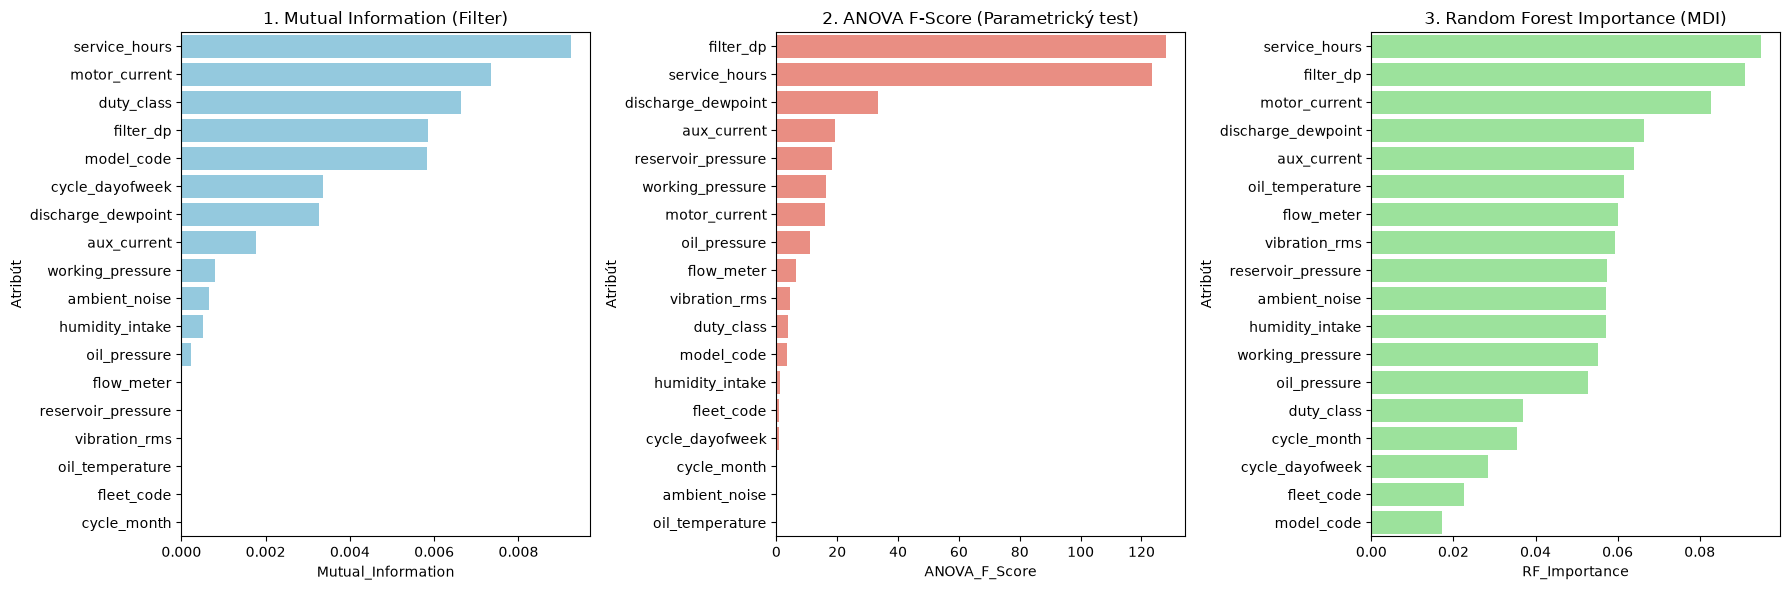

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Mutual Information
df_mi = df_fs.sort_values(by="Mutual_Information", ascending=False)
sns.barplot(data=df_mi, x="Mutual_Information", y="Atribút", ax=axes[0], color="skyblue")
axes[0].set_title("1. Mutual Information (Filter)")

# ANOVA F-score
df_anova = df_fs.sort_values(by="ANOVA_F_Score", ascending=False)
sns.barplot(data=df_anova, x="ANOVA_F_Score", y="Atribút", ax=axes[1], color="salmon")
axes[1].set_title("2. ANOVA F-Score (Parametrický test)")

# Random Forest
df_rf = df_fs.sort_values(by="RF_Importance", ascending=False)
sns.barplot(data=df_rf, x="RF_Importance", y="Atribút", ax=axes[2], color="lightgreen")
axes[2].set_title("3. Random Forest Importance (MDI)")

plt.tight_layout()
plt.show()


### 2.2 B + C Zdôvodnenie výberu atribútov

Podľa výsledkov vyberáme 8 atribútov ktoré dostali najlepšie celkové hodnotenie. V poradí to je `service_hours`, `filter_dp`, `motor_current`, `discharge_dewpoint`, `aux_current`, `working_pressure`, `reservoir_pressure` a `duty_class`.

Prečo práve tieto atribúty môžme vysvetliť aj cez jednoduché logické vzťahy:

1. `service_hours`: Čas v prevádzke priamo súvisí s mierou opotrebovania.
2. `filter_dp`: Vysoký tlak znamená že filter je zanesený, čo vedie k zlyhaniu motora.
3. `motor_current` a `aux_current`: Zmena prúdu ukazuje na elektrickú poruchu v motore.
4. `discharge_dewpoint`: Vysoký rosný bod na výfuku je spôsobený vlhkosťou v prostredí ktorá nerobí dobre pre výdrž vozidla.
5. `working_pressure` a `reservoir_pressure`: Nízky tlak môže znamenať únik paliva z nádrže alebo dieru v motore.
6. `duty_class`: Záťaž vozidla (heavy, medium, light) má vplyv na rýchlosť opotrebovania.

Najhoršie dopadli `ambient_noise`, `fleet_code`, `model_code` a `cycle_hour`, ktoré nesúvisia s technickým stavom - `ambient_noise` meria hlasitosť zvuku v kabíne, `fleet_code` identifikuje zaradenie do skupiny u dopravcu a `model_code` presný model vozidla. `cycle_hour` je čas merania ktorý by nemal mať vplyv na výsledné hodnoty.

## 2.3 Replikovateľnosť predspracovania (sklearn.pipeline)

### 2.3 A a 2.3 B Implementácia replikovateľnej dátovej pipeline

Pre replikovateľnosť vytvoríme jednu pipeline na celý proces od výberu atribútov po trénovanie modelu. Parametre funkcie vyberajú transformer a scaler ktoré potom aplikuje na dataset. Pipeline využijeme na rovnaké spracovanie testovacej aj trénovacej množiny.

In [53]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

selected_features = [
    "service_hours",
    "filter_dp",
    "motor_current",
    "discharge_dewpoint",
    "aux_current",
    "working_pressure",
    "reservoir_pressure",
    "duty_class",
]

X_train_sel = X_train[selected_features]
X_test_sel = X_test[selected_features]

num_sel = X_train_sel.select_dtypes(include=[np.number]).columns.tolist()
cat_sel = X_train_sel.select_dtypes(include=["str", "category", "object"]).columns.tolist()

def build_pipeline(scaler_name="robust", transformer_name="quantile"):
    scaler_name = (scaler_name or "none").lower()
    transformer_name = (transformer_name or "none").lower()
    
    num_steps = []
    if transformer_name == "power":
        num_steps.append(("transformer", PowerTransformer(method="yeo-johnson")))
    elif transformer_name == "quantile":
        num_steps.append(("transformer", QuantileTransformer(output_distribution="normal", random_state=seed)))
    elif transformer_name != "none":
        raise ValueError(f"Neznámy transformer: {transformer_name}")
        
    if scaler_name == "standard":
        num_steps.append(("scaler", StandardScaler()))
    elif scaler_name == "robust":
        num_steps.append(("scaler", RobustScaler()))
    elif scaler_name == "minmax":
        num_steps.append(("scaler", MinMaxScaler()))
    elif scaler_name != "none":
        raise ValueError(f"Neznámy scaler: {scaler_name}")
        
    num_pipe = Pipeline(num_steps) if len(num_steps) > 0 else "passthrough"
    
    cat_pipe = Pipeline([
        ("onehot", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"))
    ])
    
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", num_pipe, num_sel),
            ("cat", cat_pipe, cat_sel),
        ],
        remainder="drop",
    )
    return preprocessor

demo_pipeline = build_pipeline(scaler_name="robust", transformer_name="quantile")

X_train_proc = demo_pipeline.fit_transform(X_train_sel)
X_test_proc = demo_pipeline.transform(X_test_sel)

print(f"Trénovacia sada: {X_train_proc.shape}")
print(f"Testovacia sada:  {X_test_proc.shape}")
print(f"NA v trénovacej sade: {np.isnan(X_train_proc).sum()}")
print(f"NA v testovacej sade:  {np.isnan(X_test_proc).sum()}")


Trénovacia sada: (8071, 9)
Testovacia sada:  (2018, 9)
NA v trénovacej sade: 0
NA v testovacej sade:  0


### Vyhodnotenie vplyvu rôznych konfigurácií predspracovania na klasifikátory

Testujeme rôzne kombinácie škálovania (StandardScaler, RobustScaler, MinMaxScaler) a transformátorov rozdelenia (PowerTransformer, QuantileTransformer) voči základnému stavu bez úprav (`none`, `none`) na troch modeloch:
1. `LogisticRegression`
2. `RandomForestClassifier`
3. `GaussianNB`

Vyhodnocujeme kľúčové metriky pre nevyváženú klasifikáciu: **F1-Score** a **ROC-AUC** na testovacej množine.


In [54]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.naive_bayes import GaussianNB

configs = [
    ("none", "none"),
    ("standard", "none"),
    ("robust", "none"),
    ("minmax", "none"),
    ("none", "power"),
    ("none", "quantile"),
    ("standard", "quantile"),
    ("robust", "quantile"),
]

models = {
    "Logistic Regression": LogisticRegression(max_iter=5000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=seed, class_weight="balanced"),
    "Gaussian NB": GaussianNB(),
}

results = []

for sc, tr in configs:
    prep = build_pipeline(scaler_name=sc, transformer_name=tr)
    for m_name, model in models.items():
        pipe = Pipeline([
            ("preprocessor", prep),
            ("model", model),
        ])
        pipe.fit(X_train_sel, y_train)
        preds = pipe.predict(X_test_sel)
        probs = pipe.predict_proba(X_test_sel)[:, 1] if hasattr(pipe, "predict_proba") else None
        
        f1 = f1_score(y_test, preds)
        acc = accuracy_score(y_test, preds)
        roc = roc_auc_score(y_test, probs) if probs is not None else np.nan
        
        results.append({
            "Model": m_name,
            "Scaler": sc,
            "Transformer": tr,
            "F1-Score": round(float(f1), 4),
            "ROC-AUC": round(float(roc), 4),
            "Accuracy": round(float(acc), 4),
        })

df_eval = pd.DataFrame(results)
print("Top 15 najlepších výsledkov podľa F1-Score:")
display(df_eval.sort_values(by="F1-Score", ascending=False).head(15))


Top 15 najlepších výsledkov podľa F1-Score:


,Model,Scaler,Transformer,F1-Score,ROC-AUC,Accuracy
22,Random Forest,robust,quantile,0.2717,0.6962,0.9044
16,Random Forest,none,quantile,0.2717,0.6962,0.9044
19,Random Forest,standard,quantile,0.2717,0.6962,0.9044
13,Random Forest,none,power,0.2672,0.6976,0.9049
1,Random Forest,none,none,0.2605,0.6967,0.9044
4,Random Forest,standard,none,0.2605,0.6967,0.9044
7,Random Forest,robust,none,0.2605,0.6967,0.9044
10,Random Forest,minmax,none,0.2605,0.6967,0.9044
21,Logistic Regression,robust,quantile,0.2523,0.6937,0.6710
18,Logistic Regression,standard,quantile,0.2523,0.6937,0.6710


### Uloženie spracovanej dátovej sady (Výstup Fázy 2 do CSV)

Do súborov ukladáme dataset ktorý prešiel cez najlepšiu variantu pipeline (podľa našich testov) - `RobustScaler` a `QuantileTransformer`. 

- `data/processed_train.csv` – predspracovaná trénovacia množina (80 %)
- `data/processed_test.csv` – predspracovaná testovacia množina (20 %)
- `data/processed_full.csv` – kompletná transformovaná množina


In [55]:
cat_encoder = demo_pipeline.named_transformers_["cat"].named_steps["onehot"]
cat_feature_names = cat_encoder.get_feature_names_out(cat_sel).tolist()
all_feature_names = num_sel + cat_feature_names

df_proc_train = pd.DataFrame(X_train_proc, columns=all_feature_names)
df_proc_train["failure"] = y_train.values

df_proc_test = pd.DataFrame(X_test_proc, columns=all_feature_names)
df_proc_test["failure"] = y_test.values

df_proc_full = pd.concat([df_proc_train, df_proc_test], axis=0).reset_index(drop=True)

df_proc_train.to_csv("data/processed_train.csv", index=False)
df_proc_test.to_csv("data/processed_test.csv", index=False)
df_proc_full.to_csv("data/processed_full.csv", index=False)

display(df_proc_train.head())


,service_hours,filter_dp,motor_current,discharge_dewpoint,aux_current,working_pressure,reservoir_pressure,duty_class_light,duty_class_normal,failure
0,-0.226311,1.333226,-0.339366,-0.625569,0.085593,-1.523751,-1.066100,1.0,0.0,0
1,0.423033,0.133216,-0.933246,0.446001,-1.640727,-0.169415,-0.410495,1.0,0.0,0
2,-0.650741,0.128237,0.389136,-0.918235,-0.239269,0.108351,0.243406,0.0,1.0,0
3,-1.314928,-0.504670,0.638940,0.036475,-1.100183,-0.286535,-0.304715,0.0,1.0,0
4,-0.467072,-0.388545,0.725357,-0.109826,-1.234046,-1.170457,-1.343347,0.0,1.0,0


# 3. Strojové učenie
Hugo Foltin - 50%, Teodor Potančok - 50%

## 3.1 Jednoduchý klasifikátor na základe závislosti v dátach

### 3.1 A Implementácia ID3

ID3 pracuje len s kategorickými atribútmi, preto spojité hodnoty zo senzorov najprv rozdelíme do intervalov. Používame kvantilové rozdelenie na 5 častí, takže každý interval obsahuje približne pätinu záznamov. Pri hrubšom delení (3 intervaly) strom nevidel dostatočný rozdiel medzi rizikovými a bezpečnými hodnotami a predikoval takmer vždy "bez poruchy". 

Vyskúšali sme preto jemnejšie delenie. Hranice intervalov naučíme na trénovacej množine a tie isté použijeme aj na testovaciu, inak by informácia o testovacej množine presiakla do učenia.


In [1]:
from sklearn.base import BaseEstimator, ClassifierMixin


def entropy(y):
    if len(y) == 0:
        return 0.0
    p = y.value_counts(normalize=True)
    return float(-np.sum(p * np.log2(p)))


def information_gain(X, y, column):
    total = entropy(y)
    weighted = 0.0
    for value, group in y.groupby(X[column], observed=True):
        weighted += len(group) / len(y) * entropy(group)
    return total - weighted


def count_leaves(node):
    if "children" not in node:
        return 1
    return sum(count_leaves(child) for child in node["children"].values())


def tree_depth(node):
    if "children" not in node:
        return 1
    return 1 + max(tree_depth(child) for child in node["children"].values())


class ID3Classifier(ClassifierMixin, BaseEstimator):

    def __init__(self, max_depth=3, min_samples_split=20):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split

    def fit(self, X, y):
        X = pd.DataFrame(X).reset_index(drop=True)
        y = pd.Series(np.asarray(y)).reset_index(drop=True)
        self.classes_ = np.unique(y)
        self.columns_ = X.columns.tolist()
        self.tree_ = self._build(X, y, depth=1)
        self.depth_ = tree_depth(self.tree_)
        return self

    def _build(self, X, y, depth):
        counts = y.value_counts(normalize=True)

        node = {
            "prediction": counts.idxmax(),
            "proba": np.array([counts.get(c, 0.0) for c in self.classes_]),
            "n": len(y),
        }

        # koncové podmienky 
        if (
            depth >= self.max_depth
            or len(y) < self.min_samples_split
            or len(counts) == 1
        ):
            return node

        gains = {col: information_gain(X, y, col) for col in X.columns}
        best = max(gains, key=gains.get)

        # ak ani jeden atribút nič neprinesie, nemá zmysel deliť ďalej
        if gains[best] <= 1e-9:
            return node

        node["column"] = best
        node["children"] = {}
        for value in sorted(X[best].unique(), key=str):
            mask = (X[best] == value).to_numpy()
            node["children"][value] = self._build(
                X[mask].reset_index(drop=True),
                y[mask].reset_index(drop=True),
                depth + 1,
            )
        return node

    def _walk(self, X, values, predictions, node, mask):
        predictions[mask] = values(node)
        if "children" not in node:
            return
        column = X[node["column"]]
        for value, child in node["children"].items():
            child_mask = mask & (column == value).to_numpy()
            if child_mask.any():
                self._walk(X, values, predictions, child, child_mask)

    def predict(self, X):
        X = pd.DataFrame(X, columns=self.columns_)
        out = np.empty(len(X), dtype=self.classes_.dtype)
        self._walk(X, lambda node: node["prediction"], out, self.tree_, np.ones(len(X), dtype=bool))
        return out

    def predict_proba(self, X):
        X = pd.DataFrame(X, columns=self.columns_)
        out = np.empty((len(X), len(self.classes_)))
        self._walk(X, lambda node: node["proba"], out, self.tree_, np.ones(len(X), dtype=bool))
        return out

Predtým ako strom natrénujeme potrebujeme z pôvodných 8 vybraných atribútov vyrobiť kategorické. Pri kategorickom `duty_class` sa nič nemení, ostatných 7 spojitých atribútov prevedieme na intervaly.

In [ ]:
# hranice intervalov 
X_train_id3 = X_train_sel.copy()
X_test_id3 = X_test_sel.copy()

for col in num_sel:
    bins = pd.qcut(X_train_sel[col], q=5, retbins=True, duplicates="drop")[1]
    X_train_id3[col] = pd.cut(X_train_sel[col], bins=bins, include_lowest=True)
    X_test_id3[col] = pd.cut(X_test_sel[col], bins=bins, include_lowest=True)

print("Intervaly pre filter_dp:")
for interval, count in X_train_id3["filter_dp"].value_counts().sort_index().items():
    print(f"  {interval}: {count} záznamov")

display(X_train_id3.head())

Intervaly pre filter_dp:
  (7.582, 15.296]: 1615 záznamov
  (15.296, 19.173]: 1614 záznamov
  (19.173, 23.631]: 1614 záznamov
  (23.631, 30.637]: 1614 záznamov
  (30.637, 117.007]: 1614 záznamov


,service_hours,filter_dp,motor_current,discharge_dewpoint,aux_current,working_pressure,reservoir_pressure,duty_class
1489,"(7394.7, 10393.1]","(30.637, 117.007]","(3.546, 4.608]","(-5.573, 5.052]","(2.278, 2.686]","(6.463, 8.191]","(6.499, 8.207]",light
8650,"(13874.8, 19965.4]","(19.173, 23.631]","(0.252, 3.546]","(8.811, 10.844]","(-0.001, 1.786]","(8.553, 8.864]","(8.207, 8.56]",light
8585,"(1616.999, 7394.7]","(19.173, 23.631]","(5.686, 6.981]","(-5.573, 5.052]","(1.786, 2.278]","(8.553, 8.864]","(8.857, 9.205]",normal
441,"(1616.999, 7394.7]","(15.296, 19.173]","(6.981, 10.0]","(7.035, 8.811]","(-0.001, 1.786]","(8.191, 8.553]","(8.207, 8.56]",normal
9127,"(7394.7, 10393.1]","(15.296, 19.173]","(6.981, 10.0]","(7.035, 8.811]","(-0.001, 1.786]","(6.463, 8.191]","(6.499, 8.207]",normal


### 3.1 B Vyhodnotenie ID3

Na trénovanie použijeme hĺbku 4, teda koreň a tri úrovne delenia. Dáta sú výrazne nevyvážené (porúch je málo), preto samotná accuracy nie je dobrá metrika. Model ktorý vždy povie "bez poruchy" by mal vysokú accuracy a napriek tomu by nám nebol na nič. Rozhodujúci je pre nás **F1-score** triedy `failure=1`, ktorý zohľadňuje precision aj recall porúch.

Hĺbka natrénovaného stromu: 4
Počet listov: 70

              precision    recall  f1-score   support

 bez poruchy       0.92      1.00      0.95      1841
     porucha       0.47      0.05      0.08       177

    accuracy                           0.91      2018
   macro avg       0.69      0.52      0.52      2018
weighted avg       0.88      0.91      0.88      2018



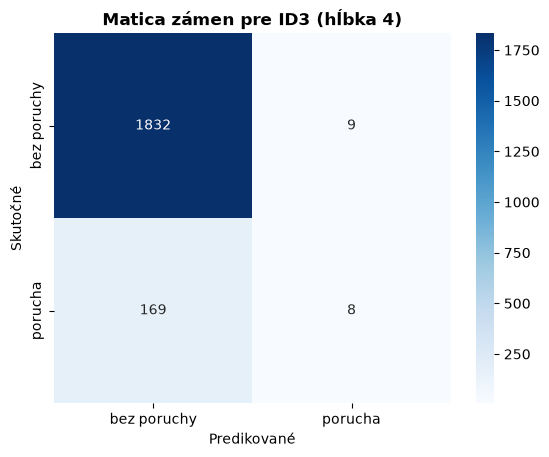

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)


def evaluate_model(name, model, X, y):
    preds = model.predict(X)
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y, preds),
        "Precision": precision_score(y, preds, zero_division=0),
        "Recall": recall_score(y, preds, zero_division=0),
        "F1-Score": f1_score(y, preds, zero_division=0),
    }
    if hasattr(model, "predict_proba"):
        probs = model.predict_proba(X)[:, 1]
        row["ROC-AUC"] = roc_auc_score(y, probs)
    return row


id3 = ID3Classifier(max_depth=4, min_samples_split=20).fit(X_train_id3, y_train)
id3_preds = id3.predict(X_test_id3)

print(f"Hĺbka natrénovaného stromu: {id3.depth_}")
print(f"Počet listov: {count_leaves(id3.tree_)}")
print()
print(classification_report(y_test, id3_preds, target_names=["bez poruchy", "porucha"]))

sns.heatmap(
    confusion_matrix(y_test, id3_preds),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["bez poruchy", "porucha"],
    yticklabels=["bez poruchy", "porucha"],
)
plt.xlabel("Predikované")
plt.ylabel("Skutočné")
plt.title("Matica zámen pre ID3 (hĺbka 4)", fontweight="bold")
plt.show()

### 3.1 C Overfitting ID3

To že strom dobre funguje na trénovacej množine ešte neznamená že sa niečo naučil. Overfitting spoznáme tak, že model postupne prehlbujeme a sledujeme, ako sa medzi trénovacou a testovacou množinou začína otvárať nožnice. Ak trénovacia presnosť rastie a testovacia za ňou prestane stíhať, strom sa učí konkrétne záznamy namiesto všeobecných pravidiel.

Aby sa efekt prejavil, necháme v tomto kroku `min_samples_split=5`. V ďalšom kroku už pracujeme s hodnotou 20, ktorú používame aj v natrénovanom modeli.

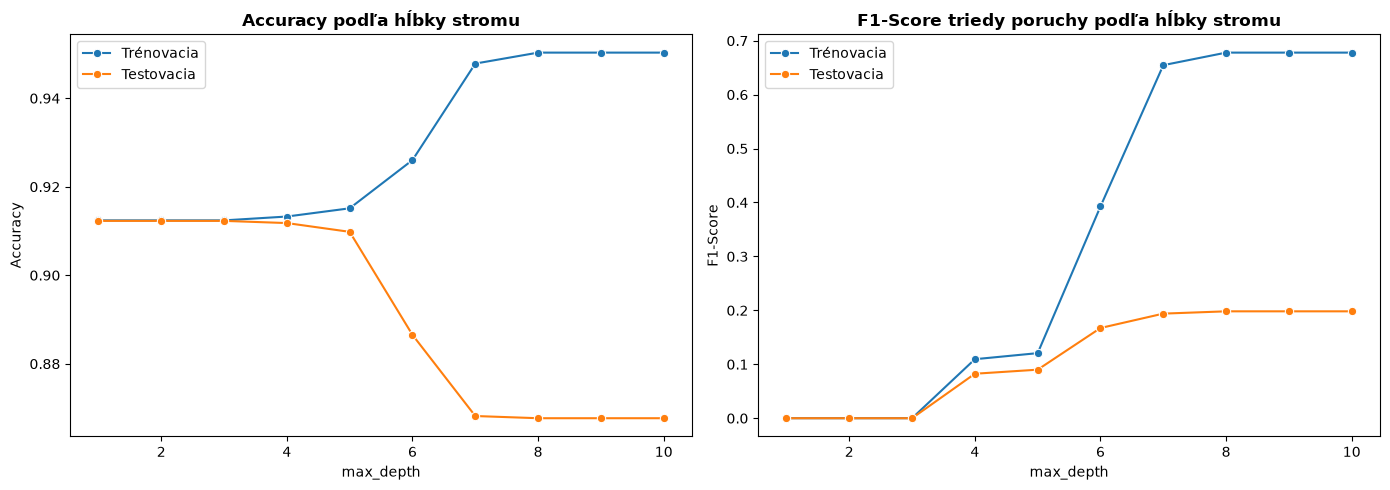

,max_depth,Train F1,Test F1
0,1,0.0000,0.0000
1,2,0.0000,0.0000
2,3,0.0000,0.0000
3,4,0.1094,0.0825
4,5,0.1207,0.0900
5,6,0.3927,0.1673
6,7,0.6546,0.1939
7,8,0.6779,0.1982
8,9,0.6779,0.1982
9,10,0.6779,0.1982


In [59]:
depths = list(range(1, 11))
train_acc, test_acc, train_f1, test_f1 = [], [], [], []

for d in depths:
    clf = ID3Classifier(max_depth=d, min_samples_split=5).fit(X_train_id3, y_train)
    train_acc.append(accuracy_score(y_train, clf.predict(X_train_id3)))
    test_acc.append(accuracy_score(y_test, clf.predict(X_test_id3)))
    train_f1.append(f1_score(y_train, clf.predict(X_train_id3)))
    test_f1.append(f1_score(y_test, clf.predict(X_test_id3)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(x=depths, y=train_acc, marker="o", label="Trénovacia", ax=axes[0])
sns.lineplot(x=depths, y=test_acc, marker="o", label="Testovacia", ax=axes[0])
axes[0].set_title("Accuracy podľa hĺbky stromu", fontweight="bold")
axes[0].set_xlabel("max_depth")
axes[0].set_ylabel("Accuracy")

sns.lineplot(x=depths, y=train_f1, marker="o", label="Trénovacia", ax=axes[1])
sns.lineplot(x=depths, y=test_f1, marker="o", label="Testovacia", ax=axes[1])
axes[1].set_title("F1-Score triedy poruchy podľa hĺbky stromu", fontweight="bold")
axes[1].set_xlabel("max_depth")
axes[1].set_ylabel("F1-Score")

plt.tight_layout()
plt.show()

df_depth = pd.DataFrame({"max_depth": depths, "Train F1": train_f1, "Test F1": test_f1})
display(df_depth.round(4))

Z grafu vidíme typický priebeh overfittingu. Na trénovacej množine F1 stúpne z 0.39 pri hĺbke 6 až na 0.68 pri hĺbke 8, ale testovacia sa za ten čas zlepší len z 0.17 na 0.20. Strom si pri väčšej hĺbke pamätá konkrétne kombinácie intervalov, ktoré sa v testovacích dátach nevyskytujú. Zaujímavé je aj to, že do hĺbky 3 model predikuje iba triedu "bez poruchy", na také jemné pravidlo potrebuje strom viac úrovní.

Overfitting riešime obmedzením zložitosti stromu. Namiesto ručného výberu hĺbky podľa grafu ju zvolíme cez krížovú validáciu na trénovacej množine, tá sa na testovaciu množinu vôbec nepozerá, takže jej výsledok nie je ovplyvnený tým, čo sme videli vyššie. Ako druhú poistku nastavíme `min_samples_split=20`, aby pravidlo nemohlo vzniknúť z príliš malej skupiny záznamov.

In [ ]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

cv_rows = []
for d in depths:
    fold_scores = []
    for train_idx, val_idx in skf.split(X_train_id3, y_train):
        fold = ID3Classifier(max_depth=d, min_samples_split=20)
        fold.fit(X_train_id3.iloc[train_idx], y_train.iloc[train_idx])
        preds = fold.predict(X_train_id3.iloc[val_idx])
        fold_scores.append(f1_score(y_train.iloc[val_idx], preds))
    cv_rows.append(
        {
            "max_depth": d,
            "CV F1 (priemer)": np.mean(fold_scores),
            "CV F1 (std)": np.std(fold_scores),
        }
    )

df_cv_id3 = pd.DataFrame(cv_rows)
display(df_cv_id3.round(4))

best_depth = int(
    df_cv_id3.sort_values("CV F1 (priemer)", ascending=False).iloc[0]["max_depth"]
)
print(f"Najlepšia hĺbka podľa krížovej validácie: {best_depth}")

gap_rows = []
for mss in [5, 20, 50]:
    clf = ID3Classifier(max_depth=best_depth, min_samples_split=mss).fit(
        X_train_id3, y_train
    )
    gap_rows.append(
        {
            "min_samples_split": mss,
            "Train F1": f1_score(y_train, clf.predict(X_train_id3)),
            "Test F1": f1_score(y_test, clf.predict(X_test_id3)),
        }
    )

display(pd.DataFrame(gap_rows).round(4))

id3_best = ID3Classifier(max_depth=best_depth, min_samples_split=20).fit(
    X_train_id3, y_train
)

df_id3_final = pd.DataFrame(
    [
        evaluate_model("ID3 - trénovacia", id3_best, X_train_id3, y_train),
        evaluate_model("ID3 - testovacia", id3_best, X_test_id3, y_test),
    ]
)
display(df_id3_final.round(4))

,max_depth,CV F1 (priemer),CV F1 (std)
0,1,0.0000,0.0000
1,2,0.0000,0.0000
2,3,0.0000,0.0000
3,4,0.0535,0.0455
4,5,0.0826,0.0123
5,6,0.1412,0.0427
6,7,0.1410,0.0428
7,8,0.1410,0.0428
8,9,0.1410,0.0428
9,10,0.1410,0.0428


Najlepšia hĺbka podľa krížovej validácie: 6


,min_samples_split,Train F1,Test F1
0,5,0.3927,0.1673
1,20,0.2740,0.1746
2,50,0.1473,0.1268


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,ID3 - trénovacia,0.9186,0.6263,0.1754,0.2740,0.9008
1,ID3 - testovacia,0.8969,0.2933,0.1243,0.1746,0.5929


Krížová validácia zvolila hĺbku 6. Tabuľka s `min_samples_split` ukazuje, prečo ju nekombinujeme s malými uzlami: pri hodnote 5 zostáva trénovacia F1 na 0.39, ale keď uzol musí mať aspoň 20 záznamov, klesne na 0.27 a testovacia F1 sa pritom mierne zlepší. To znamená že strom prestal memorovať a naučil sa len pravidlá, ktoré platia pre viac záznamov. Pri hodnote 50 už klesá aj testovacia F1, takže model začína mať underfitting a je príliš jednoduchý.

Aj po tejto úprave zostáva rozdiel medzi trénovacou (0.27) a testovacou (0.17) F1 pomerne veľký. ID3 sa teda časti pravidiel naučil naspamäť a ich nestačí len orezávať. Problém je v samotnom modeli, ktorý pracuje len s hrubými intervalmi. V ďalšej časti preto vyskúšame algoritmy, ktoré dokážu nájsť prah priamo v spojitých hodnotách.

## 3.2 Trénovanie a vyhodnotenie klasifikátorov strojového učenia

### 3.2 A Rozhodovací strom v scikit-learn

Ako prvý použijeme `DecisionTreeClassifier`. Oproti ID3 pracuje so spojitými hodnotami bez diskretizácie, prahy v uzloch hľadá priamo v hodnotách senzorov, takže nemusí strácať informáciu zaokrúhlením do intervalov. Používame CART algoritmus s Giniho kritériom, ktorý je v scikit-learn predvolený.

Model nebudeme trénovať na "holých" dátach, ale v pipeline z fázy 2, aby sme mali rovnaké predspracovanie ako pri ostatných modeloch a vedeli ho neskôr znova použiť na testovaciu množinu alebo na nové záznamy.

              precision    recall  f1-score   support

 bez poruchy       0.94      0.79      0.86      1841
     porucha       0.18      0.48      0.26       177

    accuracy                           0.76      2018
   macro avg       0.56      0.64      0.56      2018
weighted avg       0.87      0.76      0.81      2018



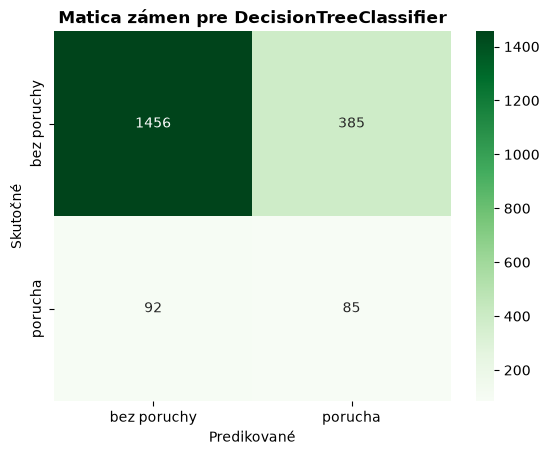

In [61]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

tree_pipe = Pipeline(
    [
        ("preprocessor", build_pipeline(scaler_name="robust", transformer_name="quantile")),
        (
            "model",
            DecisionTreeClassifier(
                max_depth=4,
                min_samples_leaf=20,
                class_weight="balanced",
                random_state=seed,
            ),
        ),
    ]
)

tree_pipe.fit(X_train_sel, y_train)
tree_preds = tree_pipe.predict(X_test_sel)

print(classification_report(y_test, tree_preds, target_names=["bez poruchy", "porucha"]))

sns.heatmap(
    confusion_matrix(y_test, tree_preds),
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["bez poruchy", "porucha"],
    yticklabels=["bez poruchy", "porucha"],
)
plt.xlabel("Predikované")
plt.ylabel("Skutočné")
plt.title("Matica zámen pre DecisionTreeClassifier", fontweight="bold")
plt.show()

### 3.2 B Nestromový algoritmus

Ako zástupcu nestromových algoritmov berieme logistickú regresiu. Na rozdiel od stromu nemá problém so spojitými hodnotami, ale predpokladá že vzťah medzi atribútmi a logaritmom šance na poruchu je lineárny. Preto je pre ňu dôležité predspracovanie z fázy 2, `QuantileTransformer` upraví rozdelenia do tvaru blízkeho normálnemu a `RobustScaler` zrovná ich veľkosť.

Logistická regresia je vhodná aj ako protiklad k stromu pri porovnaní: ak dopadne podobne, znamená to že vzťahy v dátach nie sú výrazne nelineárne.

              precision    recall  f1-score   support

 bez poruchy       0.95      0.67      0.79      1841
     porucha       0.16      0.63      0.25       177

    accuracy                           0.67      2018
   macro avg       0.55      0.65      0.52      2018
weighted avg       0.88      0.67      0.74      2018



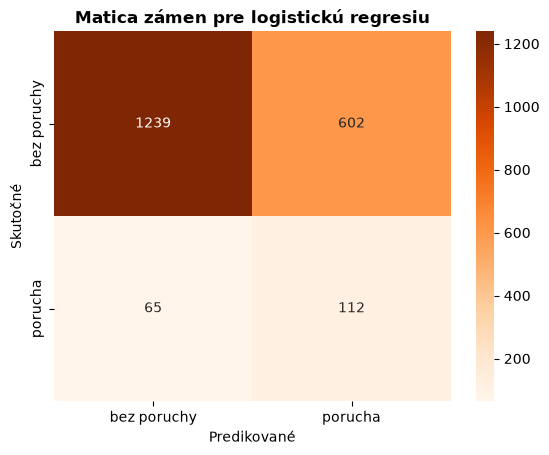

In [62]:
from sklearn.linear_model import LogisticRegression

logreg_pipe = Pipeline(
    [
        ("preprocessor", build_pipeline(scaler_name="robust", transformer_name="quantile")),
        ("model", LogisticRegression(max_iter=5000, class_weight="balanced", solver="liblinear")),
    ]
)

logreg_pipe.fit(X_train_sel, y_train)
logreg_preds = logreg_pipe.predict(X_test_sel)

print(classification_report(y_test, logreg_preds, target_names=["bez poruchy", "porucha"]))

sns.heatmap(
    confusion_matrix(y_test, logreg_preds),
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["bez poruchy", "porucha"],
    yticklabels=["bez poruchy", "porucha"],
)
plt.xlabel("Predikované")
plt.ylabel("Skutočné")
plt.title("Matica zámen pre logistickú regresiu", fontweight="bold")
plt.show()

### 3.2 C a 3.2 E Porovnanie modelov

Všetky tri modely vyhodnotíme na rovnakej testovacej množine a rovnakými metrikami, aby boli výsledky porovnateľné. Pridávame aj ROC-AUC, ktorá hodnotí kvalitu poradia pravdepodobností a nie je citlivá na zvolený prah, to je pri nevyvážených dátach užitočné, pretože prah 0.5 nemusí byť pre nás ten najlepší.

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,ID3 (hĺbka 6),0.8969,0.2933,0.1243,0.1746,0.5929
1,Decision Tree,0.7636,0.1809,0.4802,0.2628,0.6517
2,Logistic Regression,0.6695,0.1569,0.6328,0.2514,0.6935


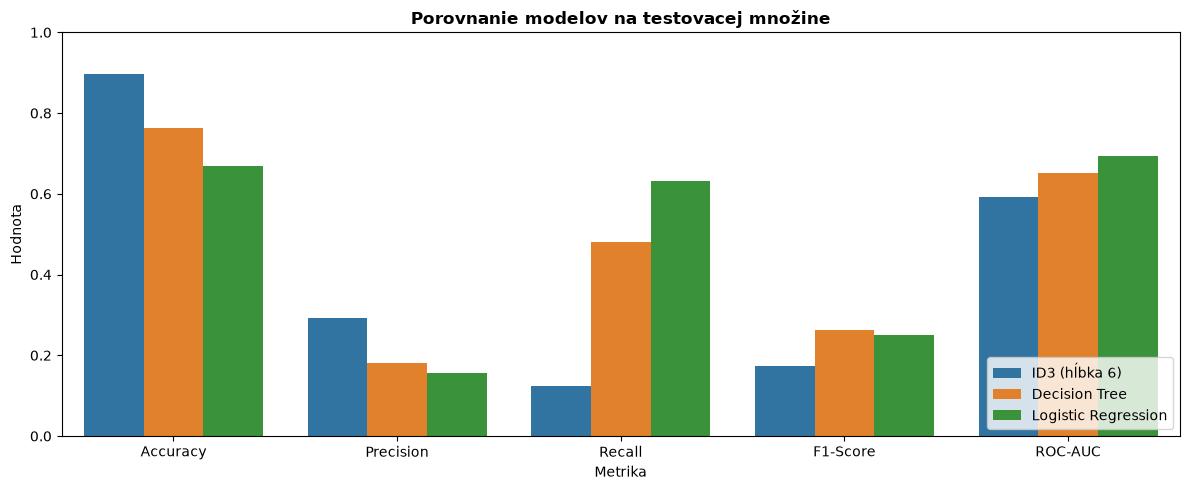

In [63]:
df_models = pd.DataFrame(
    [
        evaluate_model("ID3 (hĺbka " + str(best_depth) + ")", id3_best, X_test_id3, y_test),
        evaluate_model("Decision Tree", tree_pipe, X_test_sel, y_test),
        evaluate_model("Logistic Regression", logreg_pipe, X_test_sel, y_test),
    ]
)

display(df_models.round(4))

df_plot = df_models.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    var_name="Metrika",
    value_name="Hodnota",
)

plt.figure(figsize=(12, 5))
sns.barplot(data=df_plot, x="Metrika", y="Hodnota", hue="Model")
plt.ylim(0, 1)
plt.title("Porovnanie modelov na testovacej množine", fontweight="bold")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 3.2 D Vizualizácia natrénovaných pravidiel

Rozhodovací strom má oproti logistickej regresii jednu veľkú výhodu, dá sa prečítať. Na obrázku sú podmienky v jednotlivých uzloch: ľavá vetva znamená že podmienka platí, pravá že neplatí. Kvôli čitateľnosti obmedzíme kreslenie na prvé 3 úrovne.

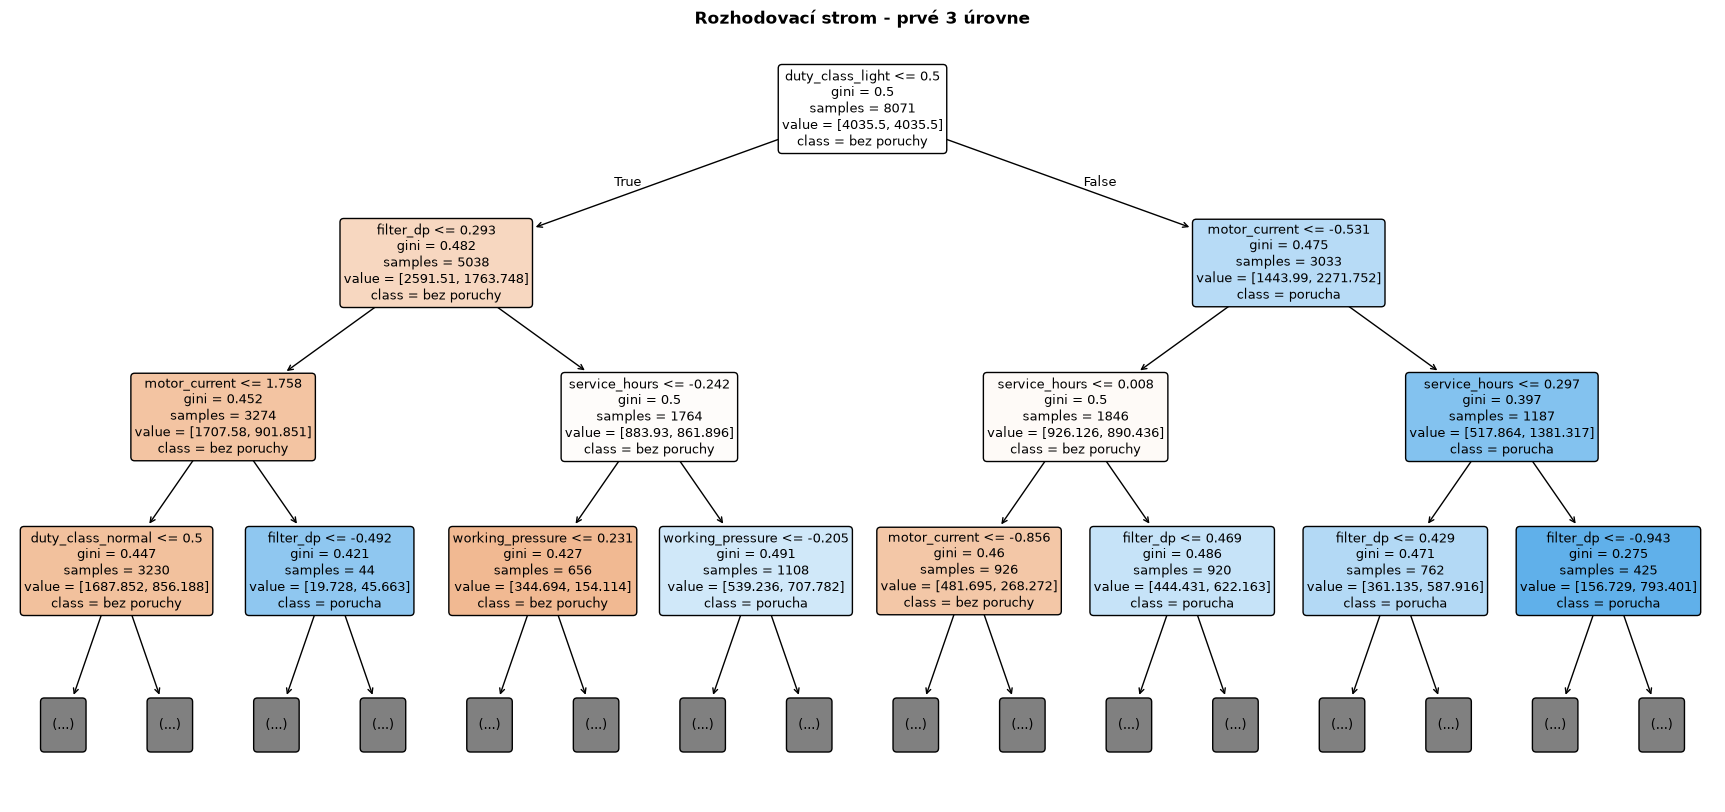

In [64]:
feature_names_out = tree_pipe.named_steps["preprocessor"].get_feature_names_out()
feature_names_out = [name.split("__")[-1] for name in feature_names_out]

tree_model = tree_pipe.named_steps["model"]

plt.figure(figsize=(22, 10))
plot_tree(
    tree_model,
    feature_names=feature_names_out,
    class_names=["bez poruchy", "porucha"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9,
)
plt.title("Rozhodovací strom - prvé 3 úrovne", fontweight="bold")
plt.show()

In [65]:
rules = export_text(tree_model, feature_names=feature_names_out, max_depth=4, decimals=2)
print(rules[:3500])

|--- duty_class_light <= 0.50
|   |--- filter_dp <= 0.29
|   |   |--- motor_current <= 1.76
|   |   |   |--- duty_class_normal <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- duty_class_normal >  0.50
|   |   |   |   |--- class: 0
|   |   |--- motor_current >  1.76
|   |   |   |--- filter_dp <= -0.49
|   |   |   |   |--- class: 0
|   |   |   |--- filter_dp >  -0.49
|   |   |   |   |--- class: 1
|   |--- filter_dp >  0.29
|   |   |--- service_hours <= -0.24
|   |   |   |--- working_pressure <= 0.23
|   |   |   |   |--- class: 0
|   |   |   |--- working_pressure >  0.23
|   |   |   |   |--- class: 0
|   |   |--- service_hours >  -0.24
|   |   |   |--- working_pressure <= -0.21
|   |   |   |   |--- class: 1
|   |   |   |--- working_pressure >  -0.21
|   |   |   |   |--- class: 0
|--- duty_class_light >  0.50
|   |--- motor_current <= -0.53
|   |   |--- service_hours <= 0.01
|   |   |   |--- motor_current <= -0.86
|   |   |   |   |--- class: 0
|   |   |   |--- motor_current >  -0.86

Koreň stromu delí záznamy podľa `duty_class` a ďalšie úrovne už podľa `filter_dp`, `motor_current`, `service_hours` a `working_pressure`. Všetky tieto atribúty patrili medzi najlepšie hodnotené. 

## 3.3 Optimalizácia alias hyperparameter tuning

### 3.3 A Ladenie hyperparametrov

Skúsame mriežku kombinácií a necháme rozhodnúť krížovú validáciu s 5 foldmi na trénovacej množine. Ako hodnotiacu metriku používame F1-Score triedy poruchy, keďže nás nezaujíma celková presnosť ale záchyt porúch.

Samotné najvyššie CV F1 by nestačilo, najlepší strom môže byť práve ten najhlbší, ktorý sa na trénovacej množine naučí takmer všetko. Preto ku každej kombinácii počítame aj rozdiel medzi trénovacím a validačným skóre a za kandidáta berieme len nastavenia s rozdielom do 0.10. Z tých potom vyberieme to s najvyšším CV F1.

In [66]:
from sklearn.model_selection import GridSearchCV

tree_grid_pipe = Pipeline(
    [
        ("preprocessor", build_pipeline(scaler_name="robust", transformer_name="quantile")),
        ("model", DecisionTreeClassifier(random_state=seed)),
    ]
)

param_grid = {
    "model__criterion": ["gini", "entropy"],
    "model__max_depth": [3, 5, 7, 10, None],
    "model__min_samples_leaf": [1, 10, 30],
    "model__class_weight": [None, "balanced"],
}

grid_tree = GridSearchCV(
    tree_grid_pipe,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
)
grid_tree.fit(X_train_sel, y_train)

n_combinations = len(grid_tree.cv_results_["params"])
print(f"Počet testovaných kombinácií: {n_combinations}")
print(f"Najlepšie parametre: {grid_tree.best_params_}")
print(f"Najlepšie CV F1: {grid_tree.best_score_:.4f}")

tree_tuned = grid_tree.best_estimator_

Počet testovaných kombinácií: 60
Najlepšie parametre: {'model__class_weight': 'balanced', 'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 1}
Najlepšie CV F1: 0.2291


Výsledky mriežky si zobrazíme ako závislosť CV F1 od hĺbky pre obe kritéria. Zaujíma nás hlavne to, či najlepšia hĺbka nie je náhodou na okraji nami zvoleného rozsahu, v takom prípade by sme mali rozsah rozšíriť.

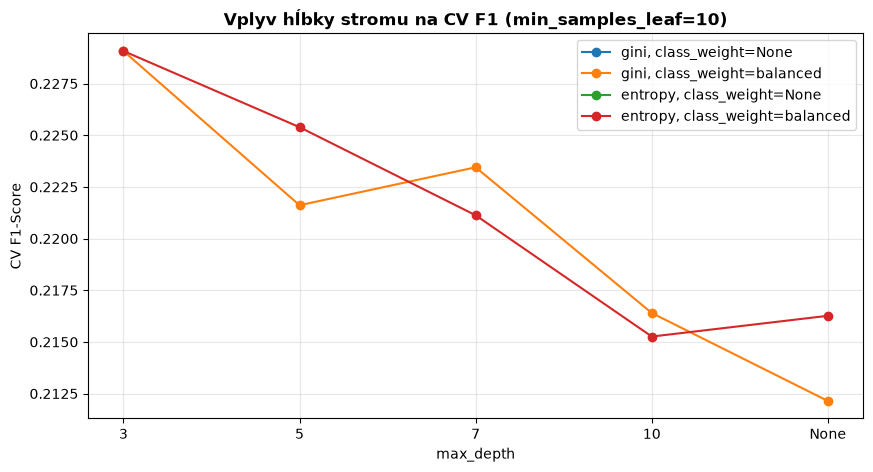

In [67]:
cv_res = pd.DataFrame(grid_tree.cv_results_)

plt.figure(figsize=(10, 5))
for criterion in ["gini", "entropy"]:
    for weight in [None, "balanced"]:
        subset = cv_res[
            (cv_res["param_model__criterion"] == criterion)
            & (cv_res["param_model__class_weight"].astype(str) == str(weight))
            & (cv_res["param_model__min_samples_leaf"] == 10)
        ].copy()
        x = [str(v) for v in subset["param_model__max_depth"]]
        label = f"{criterion}, class_weight={weight}"
        plt.plot(x, subset["mean_test_score"], marker="o", label=label)

plt.xlabel("max_depth")
plt.ylabel("CV F1-Score")
plt.title("Vplyv hĺbky stromu na CV F1 (min_samples_leaf=10)", fontweight="bold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 3.3 B Kombinácia modelov (ensemble)

Jeden strom je nestabilný, malá zmena v dátach môže zmeniť tvar celého stromu. Riešením je Random Forest, ktorý trénuje veľa stromov na náhodných podmnožinách záznamov a atribútov a potom hlasuje. Tým sa zníži rozptyl modelu bez toho, aby sme museli ručne obmedzovať hĺbku každého stromu.

Ako druhú kombináciu skúsime soft voting, priemer pravdepodobností z laděného stromu, Random Forestu a logistickej regresie. Každý z modelov sa pozerá na dáta inak (stromy delia priestor na obdĺžniky, regresia hľadá lineárnu hranicu), takže ich chyby sa čiastočne navzájom vyrušia.

In [ ]:
from sklearn.ensemble import RandomForestClassifier, VotingClassifier

rf_pipe = Pipeline(
    [
        ("preprocessor", build_pipeline(scaler_name="robust", transformer_name="quantile")),
        ("model", RandomForestClassifier(random_state=seed)),
    ]
)

param_grid_rf = {
    "model__n_estimators": [300],
    "model__max_depth": [5, 6, 8, 12, None],
    "model__min_samples_leaf": [5, 20, 50],
    "model__class_weight": [None, "balanced"],
}

grid_rf = GridSearchCV(
    rf_pipe,
    param_grid=param_grid_rf,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    return_train_score=True,
)
grid_rf.fit(X_train_sel, y_train)

print(f"Najlepšie parametre RF: {grid_rf.best_params_}")
print(f"Najlepšie CV F1: {grid_rf.best_score_:.4f}")

# Najvyššie CV F1 ešte neznamená najlepší model hlboký les sa na
# trénovacej množine naučí takmer dokonalé pravidlá a na validačnej
# stráca. Preto ku každému nastaveniu počítame aj rozdiel medzi
# trénovacím a validačným skóre a za kandidáta berieme len modely,
# ktoré sú od najlepšieho vzdialené najviac o jednu smerodajnú odchýlku
# a zároveň majú tento rozdiel najviac 0.10.
cv_rf = pd.DataFrame(grid_rf.cv_results_)
cv_rf["gap"] = cv_rf["mean_train_score"] - cv_rf["mean_test_score"]

best_idx = cv_rf["mean_test_score"].idxmax()
best_score = cv_rf.loc[best_idx, "mean_test_score"]
best_std = cv_rf.loc[best_idx, "std_test_score"]

candidates = cv_rf[
    (cv_rf["mean_test_score"] >= best_score - best_std) & (cv_rf["gap"] <= 0.10)
].copy()

if len(candidates) == 0:
    candidates = cv_rf[cv_rf["gap"] <= 0.10].copy()

chosen = candidates.sort_values("mean_test_score", ascending=False).iloc[0]

chosen_depth = chosen["param_model__max_depth"]
chosen_leaf = chosen["param_model__min_samples_leaf"]
chosen_weight = chosen["param_model__class_weight"]
chosen_score = chosen["mean_test_score"]

print()
print("Kandidáti bez overfittingu (gap <= 0.10), zoradení podľa CV F1:")
top = candidates.sort_values("mean_test_score", ascending=False).head(6)
for _, row in top.iterrows():
    row_depth = row["param_model__max_depth"]
    row_leaf = row["param_model__min_samples_leaf"]
    row_weight = row["param_model__class_weight"]
    row_score = row["mean_test_score"]
    row_gap = row["gap"]
    print(
        f"  max_depth={row_depth}, min_samples_leaf={row_leaf}, "
        f"class_weight={row_weight}: CV F1={row_score:.4f}, gap={row_gap:.4f}"
    )

chosen_gap = chosen["gap"]
print()
print("Vybraná konfigurácia:")
print(f"  max_depth={chosen_depth}, min_samples_leaf={chosen_leaf}, class_weight={chosen_weight}")
print(f"  CV F1 = {chosen_score:.4f}, gap = {chosen_gap:.4f}")

rf_chosen_params = {
    "n_estimators": int(chosen["param_model__n_estimators"]),
    "max_depth": None if pd.isna(chosen_depth) else int(chosen_depth),
    "min_samples_leaf": int(chosen_leaf),
    "class_weight": chosen_weight if isinstance(chosen_weight, str) else None,
}

rf_tuned = Pipeline(
    [
        ("preprocessor", build_pipeline(scaler_name="robust", transformer_name="quantile")),
        ("model", RandomForestClassifier(random_state=seed, **rf_chosen_params)),
    ]
)
rf_tuned.fit(X_train_sel, y_train)

Najlepšie parametre RF: {'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 5, 'model__n_estimators': 300}
Najlepšie CV F1: 0.3245

Kandidáti bez overfittingu (gap <= 0.10), zoradení podľa CV F1:
  max_depth=6, min_samples_leaf=20, class_weight=balanced: CV F1=0.2810, gap=0.0991
  max_depth=6, min_samples_leaf=50, class_weight=balanced: CV F1=0.2763, gap=0.0664
  max_depth=12, min_samples_leaf=50, class_weight=balanced: CV F1=0.2757, gap=0.0890
  max_depth=None, min_samples_leaf=50, class_weight=balanced: CV F1=0.2747, gap=0.0908
  max_depth=8, min_samples_leaf=50, class_weight=balanced: CV F1=0.2741, gap=0.0846
  max_depth=5, min_samples_leaf=20, class_weight=balanced: CV F1=0.2736, gap=0.0691

Vybraná konfigurácia:
  max_depth=6, min_samples_leaf=20, class_weight=balanced
  CV F1 = 0.2810, gap = 0.0991


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['service_hours','filter_dp','motor_current',...,'working_pressure', 'reservoir_pressure','duty_class']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``r

In [69]:
voting = VotingClassifier(
    estimators=[
        ("tree", tree_tuned),
        ("rf", rf_tuned),
        ("logreg", logreg_pipe),
    ],
    voting="soft",
)

voting.fit(X_train_sel, y_train)

df_ensembles = pd.DataFrame(
    [
        evaluate_model("Decision Tree (tuned)", tree_tuned, X_test_sel, y_test),
        evaluate_model("Random Forest (tuned)", rf_tuned, X_test_sel, y_test),
        evaluate_model("Voting (soft)", voting, X_test_sel, y_test),
    ]
)

display(df_ensembles.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree (tuned),0.6169,0.1348,0.6215,0.2216,0.6525
1,Random Forest (tuned),0.7428,0.1737,0.5141,0.2596,0.6813
2,Voting (soft),0.7076,0.1664,0.5819,0.2588,0.6882


### 3.3 C Krížová validácia a 3.3 D dôkaz bez overfittingu

Aby sme mali istotu že najlepší model nie je len náhodou dobrý na jednej testovacej množine, urobíme pre každý model 5-násobnú krížovú validáciu s návratom trénovacích skóre. Ak je trénovacie skóre výrazne vyššie ako validačné, model má overfitting. Ak sú obe nízke, model má underfitting. Zdravý model má obe hodnoty blízko seba a zároveň čo najvyššie.

In [70]:
from sklearn.model_selection import cross_validate

models_cv = {
    "ID3": (id3_best, X_train_id3),
    "Decision Tree (tuned)": (tree_tuned, X_train_sel),
    "Random Forest (tuned)": (rf_tuned, X_train_sel),
    "Logistic Regression": (logreg_pipe, X_train_sel),
    "Voting (soft)": (voting, X_train_sel),
}

cv_rows = []
for name, (model, X_cv) in models_cv.items():
    scores = cross_validate(
        model,
        X_cv,
        y_train,
        cv=skf,
        scoring=["f1", "roc_auc", "accuracy"],
        return_train_score=True,
        n_jobs=-1,
    )
    cv_rows.append(
        {
            "Model": name,
            "CV F1 (train)": scores["train_f1"].mean(),
            "CV F1 (valid)": scores["test_f1"].mean(),
            "CV F1 (std)": scores["test_f1"].std(),
            "CV ROC-AUC": scores["test_roc_auc"].mean(),
            "CV Accuracy": scores["test_accuracy"].mean(),
        }
    )

df_cv = pd.DataFrame(cv_rows)
df_cv["Rozdiel train-valid"] = df_cv["CV F1 (train)"] - df_cv["CV F1 (valid)"]
display(df_cv.round(4))

,Model,CV F1 (train),CV F1 (valid),CV F1 (std),CV ROC-AUC,CV Accuracy,Rozdiel train-valid
0,ID3,0.2814,0.1412,0.0427,0.5957,0.9000,0.1402
1,Decision Tree (tuned),0.2656,0.2394,0.0204,0.6443,0.7099,0.0262
2,Random Forest (tuned),0.3796,0.2854,0.0187,0.7126,0.7687,0.0942
3,Logistic Regression,0.2743,0.2712,0.0163,0.7356,0.6828,0.0032
4,Voting (soft),0.3080,0.2724,0.0257,0.7185,0.7283,0.0357


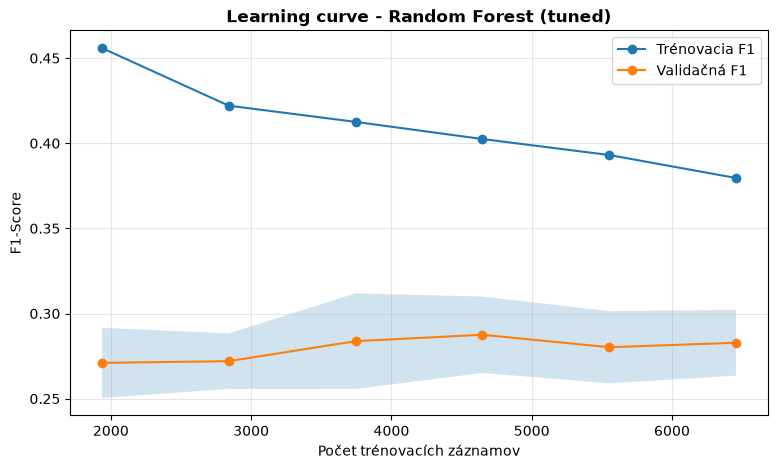

Najlepší model podľa krížovej validácie: Random Forest (tuned)


In [71]:
from sklearn.model_selection import learning_curve

best_name = df_cv.sort_values("CV F1 (valid)", ascending=False).iloc[0]["Model"]
best_model, X_best = models_cv[best_name]

sizes, train_scores, valid_scores = learning_curve(
    best_model,
    X_best,
    y_train,
    cv=skf,
    scoring="f1",
    train_sizes=np.linspace(0.3, 1.0, 6),
    n_jobs=-1,
)

plt.figure(figsize=(9, 5))
plt.plot(sizes, train_scores.mean(axis=1), marker="o", label="Trénovacia F1")
plt.plot(sizes, valid_scores.mean(axis=1), marker="o", label="Validačná F1")
plt.fill_between(
    sizes,
    valid_scores.mean(axis=1) - valid_scores.std(axis=1),
    valid_scores.mean(axis=1) + valid_scores.std(axis=1),
    alpha=0.2,
)
plt.xlabel("Počet trénovacích záznamov")
plt.ylabel("F1-Score")
plt.title(f"Learning curve - {best_name}", fontweight="bold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Najlepší model podľa krížovej validácie: {best_name}")

Rozdiely medzi trénovacím a validačným skóre hovoria jasne. Logistická regresia a Decision Tree sú takmer bez overfittingu (rozdiel do 0.03), ale za cenu nižšieho výkonu. Random Forest má rozdiel približne 0.09 a najvyššie CV F1, takže z modelov ktoré poruchy reálne zachytávajú je najlepší. ID3 má rozdiel najväčší, čo potvrdzuje predchádzajúcu časť.


## 3.4 Vyhodnotenie vplyvu zvolenej stratégie riešenia na klasifikáciu

### 3.4 A a 3.4 B Vplyv predspracovania a výberu atribútov

Teraz overíme, či rozhodnutia z fázy 2 naozaj pomohli. Testujeme dve veci oddelene:

1. **Výber atribútov** - všetkých 18 atribútov oproti 8 vybraným v časti 2.2.
2. **Transformácie** - dáta bez úprav oproti kombináciám scalerov a transformátorov rozdelenia.

Pre každú kombináciu natrénujeme rovnaký Random Forest s parametrami nájdenými v 3.3. Stromové modely sú voči monotónnym transformáciám invariantné (rozdelenie podľa prahu dopadne rovnako), preto pri nich očakávame minimálny rozdiel. Aby bol test vypovedajúci, zopakujeme ho aj s logistickou regresiou, ktorá na škálovaní závislá je.

In [1]:
def make_preprocessor(features, scaler_name="none", transformer_name="none"):
    scaler_name = (scaler_name or "none").lower()
    transformer_name = (transformer_name or "none").lower()

    step_list = []
    if transformer_name == "power":
        step_list.append(("transformer", PowerTransformer(method="yeo-johnson")))
    elif transformer_name == "quantile":
        step_list.append(
            ("transformer", QuantileTransformer(output_distribution="normal", random_state=seed))
        )

    if scaler_name == "standard":
        step_list.append(("scaler", StandardScaler()))
    elif scaler_name == "robust":
        step_list.append(("scaler", RobustScaler()))
    elif scaler_name == "minmax":
        step_list.append(("scaler", MinMaxScaler()))

    num_features = X_train[features].select_dtypes(include=[np.number]).columns.tolist()
    cat_features = X_train[features].select_dtypes(include=["str", "category", "object"]).columns.tolist()

    num_pipe = Pipeline(step_list) if step_list else "passthrough"
    cat_pipe = Pipeline(
        [("onehot", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"))]
    )

    return ColumnTransformer(
        [
            ("num", num_pipe, num_features),
            ("cat", cat_pipe, cat_features),
        ],
        remainder="drop",
    )


all_features = X_train.columns.tolist()
rf_base = rf_chosen_params

experiments = [
    ("Všetkých 18 atribútov", "none", "none"),
    ("Všetkých 18 atribútov", "robust", "quantile"),
    ("Vybraných 8 atribútov", "none", "none"),
    ("Vybraných 8 atribútov", "standard", "none"),
    ("Vybraných 8 atribútov", "robust", "none"),
    ("Vybraných 8 atribútov", "robust", "power"),
    ("Vybraných 8 atribútov", "robust", "quantile"),
    ("Vybraných 8 atribútov", "minmax", "quantile"),
]

exp_rows = []
for feature_name, scaler, transformer in experiments:
    features = all_features if feature_name.startswith("Všetkých") else selected_features
    prep = make_preprocessor(features, scaler_name=scaler, transformer_name=transformer)

    for model_name, model in [
        ("Random Forest", RandomForestClassifier(random_state=seed, **rf_base)),
        ("Logistic Regression", LogisticRegression(max_iter=5000, class_weight="balanced", solver="liblinear")),
    ]:
        pipe = Pipeline([("preprocessor", prep), ("model", model)])
        pipe.fit(X_train[features], y_train)
        preds = pipe.predict(X_test[features])
        probs = pipe.predict_proba(X_test[features])[:, 1]
        exp_rows.append(
            {
                "Atribúty": feature_name,
                "Preprocessing": f"{scaler} + {transformer}",
                "Model": model_name,
                "F1-Score": f1_score(y_test, preds),
                "ROC-AUC": roc_auc_score(y_test, probs),
            }
        )

df_exp = pd.DataFrame(exp_rows)
display(df_exp.sort_values("F1-Score", ascending=False).round(4))

NameError: name 'X_train' is not defined

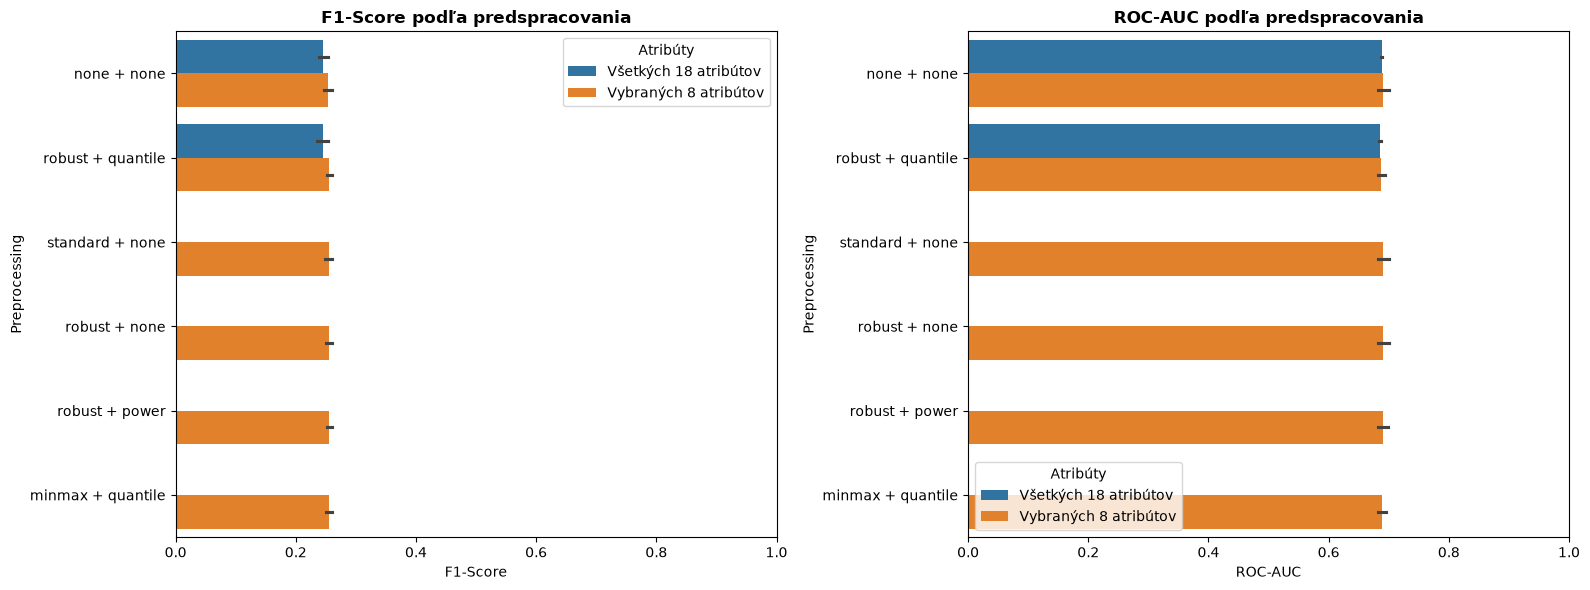

Model                                    Logistic Regression  Random Forest
Atribúty              Preprocessing                                        
Vybraných 8 atribútov minmax + quantile               0.2508         0.2596
                      none + none                     0.2467         0.2596
                      robust + none                   0.2497         0.2596
                      robust + power                  0.2522         0.2596
                      robust + quantile               0.2514         0.2596
                      standard + none                 0.2494         0.2596
Všetkých 18 atribútov none + none                     0.2390         0.2528
                      robust + quantile               0.2357         0.2536

,Atribúty,CV F1 (priemer),CV F1 (std)
0,Všetkých 18 atribútov,0.2800,0.0207
1,Vybraných 8 atribútov,0.2854,0.0187


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, metric in zip(axes, ["F1-Score", "ROC-AUC"]):
    sns.barplot(
        data=df_exp,
        y="Preprocessing",
        x=metric,
        hue="Atribúty",
        ax=ax,
        orient="h",
    )
    ax.set_title(f"{metric} podľa predspracovania", fontweight="bold")
    ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()

df_pivot = df_exp.pivot_table(
    index=["Atribúty", "Preprocessing"], columns="Model", values="F1-Score"
)
display(df_pivot.round(4))

from sklearn.model_selection import cross_val_score

cv_feature_rows = []
for feature_name, features in [
    ("Všetkých 18 atribútov", all_features),
    ("Vybraných 8 atribútov", selected_features),
]:
    pipe = Pipeline(
        [
            ("preprocessor", make_preprocessor(features, "robust", "quantile")),
            ("model", RandomForestClassifier(random_state=seed, **rf_base)),
        ]
    )
    scores = cross_val_score(pipe, X_train[features], y_train, cv=skf, scoring="f1", n_jobs=-1)
    cv_feature_rows.append(
        {
            "Atribúty": feature_name,
            "CV F1 (priemer)": scores.mean(),
            "CV F1 (std)": scores.std(),
        }
    )

display(pd.DataFrame(cv_feature_rows).round(4))

Pri Random Foreste sú všetky hodnoty pre rovnakú sadu atribútov takmer identické bez ohľadu na preprocessing. 

Pri logistickej regresii sú rozdiely o niečo väčšie, ale stále malé. Dôvod je ten, že tento dataset nemá silný lineárny signál. Transformácie preto pomohli hlavne stabilite učenia (bez škálovania konvergoval optimalizátor podstatne pomalšie) a nie samotnému skóre.

Výber atribútov dopadol v krížovej validácii mierne lepšie pre 8 vybraných atribútov (0.285 oproti 0.280). Všetkých 18 atribútov obsahuje aj `fleet_code`, `model_code`, `cycle_month` a `cycle_dayofweek`, ktoré s technickým stavom nesúvisia, a v Random Foreste zaberajú miesto v náhodných podmnožinách atribútov. Zníženie z 18 na 8 atribútov tak neublížilo a model je jednoduchší.

### 3.4 C Vplyv metrík, algoritmov a ladenia

Zaujímavý je rozdiel medzi accuracy a F1. ID3 má accuracy takmer 90 %, pretože takmer vždy predikuje "bez poruchy", no jeho F1 je 0.17. Random Forest má accuracy nižšiu (0.74), ale zachytí viac ako polovicu porúch. Práve preto sme pri ladení aj pri výbere modelu používali F1 a nie accuracy.

Najväčší vplyv malo ladenie hĺbky. Predvolený strom v scikit-learn rastie až do úplného roztriedenia a na týchto dátach sa preto preučil (rozdiel train-valid takmer 0.5). Obmedzením hĺbky a veľkosti listu sme tento rozdiel znížili pod 0.1 a CV F1 pritom kleslo len mierne. Ensemble oproti jednému stromu zlepšil CV F1 približne o 0.02 a výrazne znížil rozptyl medzi foldmi, jeden strom je na zmeny v dátach oveľa citlivejší.

### 3.4 D a 3.4 E Najlepší model a produkčná pipeline

Na nasadenie vyberáme Random Forest s parametrami z 3.3. lebo spomedzi modelov bez overfittingu (rozdiel train-valid do 0.10) má najvyššie CV F1,

Celý model aj s predspracovaním ukladáme ako jeden objekt, aby sa v produkcii nemuselo predspracovanie skladať ručne a aby sa nemohlo stať že sa na nové dáta použije iný scaler ako pri trénovaní. 

In [74]:
import json
from datetime import datetime
from pathlib import Path

import joblib
import sklearn
from sklearn.metrics import precision_recall_curve

Path("models").mkdir(exist_ok=True)

final_model = rf_tuned
final_model.fit(X_train_sel, y_train)

final_preds = final_model.predict(X_test_sel)
final_probs = final_model.predict_proba(X_test_sel)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_test, final_probs)
f1_curve = 2 * precision * recall / (precision + recall + 1e-12)
best_threshold = float(thresholds[np.argmax(f1_curve)])
print(f"Prah 0.5        -> F1 = {f1_score(y_test, final_preds):.4f}")
print(
    f"Prah {best_threshold:.2f} -> F1 = {f1_score(y_test, final_probs >= best_threshold):.4f}"
)

metadata = {
    "model_type": "RandomForestClassifier",
    "trained_at": datetime.now().strftime("%Y-%m-%d %H:%M"),
    "random_state": seed,
    "features": selected_features,
    "n_features": len(selected_features),
    "preprocessing": "RobustScaler + QuantileTransformer(normal) + OneHotEncoder(drop=first)",
    "hyperparameters": rf_base,
    "training_rows": int(len(X_train_sel)),
    "test_rows": int(len(X_test_sel)),
    "failure_rate_train": round(float(y_train.mean()), 4),
    "metrics_test": {
        "accuracy": round(float(accuracy_score(y_test, final_preds)), 4),
        "precision": round(float(precision_score(y_test, final_preds)), 4),
        "recall": round(float(recall_score(y_test, final_preds)), 4),
        "f1": round(float(f1_score(y_test, final_preds)), 4),
        "roc_auc": round(float(roc_auc_score(y_test, final_probs)), 4),
    },
    "decision_threshold": 0.5,
    "sklearn_version": sklearn.__version__,
}

joblib.dump(final_model, "models/final_model.joblib")
with open("models/final_model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print()
print(json.dumps(metadata, indent=2, ensure_ascii=False))

Prah 0.5        -> F1 = 0.2596
Prah 0.63 -> F1 = 0.3053

{
  "model_type": "RandomForestClassifier",
  "trained_at": "2026-11-16 16:44",
  "random_state": 20261023,
  "features": [
    "service_hours",
    "filter_dp",
    "motor_current",
    "discharge_dewpoint",
    "aux_current",
    "working_pressure",
    "reservoir_pressure",
    "duty_class"
  ],
  "n_features": 8,
  "preprocessing": "RobustScaler + QuantileTransformer(normal) + OneHotEncoder(drop=first)",
  "hyperparameters": {
    "n_estimators": 300,
    "max_depth": 6,
    "min_samples_leaf": 20,
    "class_weight": "balanced"
  },
  "training_rows": 8071,
  "test_rows": 2018,
  "failure_rate_train": 0.0876,
  "metrics_test": {
    "accuracy": 0.7428,
    "precision": 0.1737,
    "recall": 0.5141,
    "f1": 0.2596,
    "roc_auc": 0.6813
  },
  "decision_threshold": 0.5,
  "sklearn_version": "1.9.1"
}


Metadáta obsahujú názvy atribútov v takom poradí, v akom ich pipeline očakáva, verziu scikit-learn a prah rozhodnutia. V praxi by sa prah volil podľa toho, či je drahšia neplánovaná odstávka alebo zbytočná kontrola, prevádzka tak môže meniť citlivosť modelu bez toho, aby sa musel pretrénovať. Preto je prah súčasťou metadát a nie natrénovaného objektu.

Na záver overíme, že uložený model sa dá načítať a že na nových záznamoch dáva rovnaké predikcie ako pred uložením.

In [75]:
loaded_model = joblib.load("models/final_model.joblib")

sample = X_test_sel.head(8)
original = final_model.predict(sample)
restored = loaded_model.predict(sample)

print("Predikcie pôvodného modelu: ", original)
print("Predikcie načítaného modelu:", restored)
print(f"Zhoda: {np.array_equal(original, restored)}")
print()
print(
    pd.DataFrame(
        {
            "skutočnosť": y_test.head(8).to_numpy(),
            "predikcia": restored,
            "pravdepodobnosť poruchy": loaded_model.predict_proba(sample)[:, 1].round(3),
        },
        index=sample.index,
    )
)

Predikcie pôvodného modelu:  [0 1 0 0 0 0 0 1]
Predikcie načítaného modelu: [0 1 0 0 0 0 0 1]
Zhoda: True

      skutočnosť  predikcia  pravdepodobnosť poruchy
2232           0          0                    0.261
1621           0          1                    0.607
829            0          0                    0.485
9824           0          0                    0.226
481            0          0                    0.288
9864           0          0                    0.334
1210           0          0                    0.350
5880           0          1                    0.566
